# Measure your noise floor before believing a lever

*By [Georgy Mamarin](https://www.kaggle.com/georgymamarin)*

This is a diagnostic for [ROGII &mdash; Wellbore Geology Prediction](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction). I resubmitted five kernels sitting in my own account, fourteen times between them, changing nothing inside any of them, and half the conclusions I had drawn from single scores did not survive what came back.


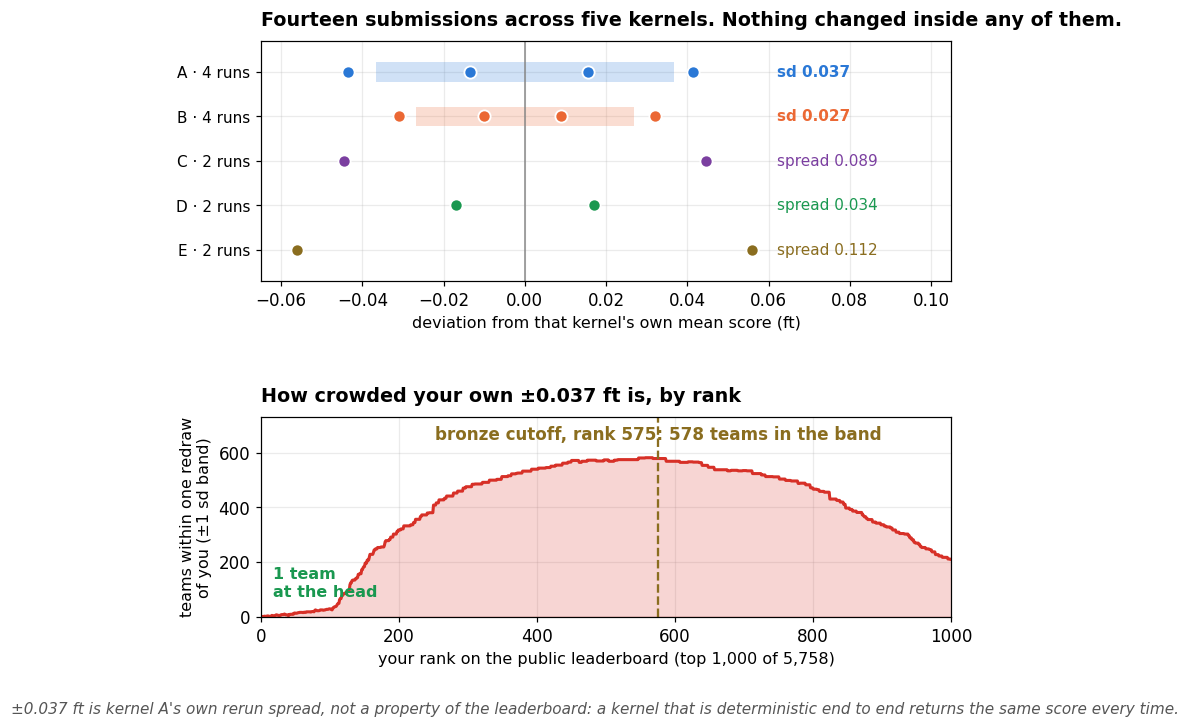

In [1]:
# Hero figure. Top: two public forks in my account, each resubmitted with no edits between runs.
# Bottom: how many teams sit inside that spread at each rank (band width, not displacement).
# Leaderboard snapshot is public information, taken 2026-07-26 (top 2200 of 5758 teams);
# it is embedded because this notebook runs without internet access.
# Sized for Kaggle's ~730px body: 8.1in wide, fonts >=10.
import numpy as np, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})

A = np.array([6.700, 6.726, 6.641, 6.671])          # fork A (ayodeji v599), 4 reruns, nothing changed
B = np.array([7.219, 7.240, 7.259, 7.282])          # fork B (baidalinadilzhan), 4 reruns, nothing changed
CC = np.array([7.216, 7.305])                       # kernel C (aevionlabs family), 2 reruns
DD = np.array([7.246, 7.280])                       # kernel D (bernubritz rebuild), 2 reruns
EE = np.array([7.535, 7.647])                       # kernel E (a fork plus my own corrector), 2 reruns
BRONZE = 6.470
LB = np.array([4.679,4.902,5.064,5.108,5.237,5.265,5.325,5.386,5.443,5.444,5.453,5.551,5.606,5.648,5.661,5.697,5.707,5.714,5.718,5.840,5.864,5.868,5.870,5.899,5.901,5.902,5.939,5.945,5.954,5.967,5.979,5.981,5.998,6.003,6.012,6.021,6.022,6.038,6.039,6.060,6.077,6.104,6.104,6.106,6.107,6.112,6.114,6.132,6.137,6.148,6.153,6.157,6.164,6.168,6.173,6.179,6.181,6.183,6.187,6.188,6.197,6.203,6.207,6.210,6.211,6.220,6.232,6.238,6.238,6.241,6.243,6.248,6.249,6.252,6.255,6.256,6.259,6.264,6.269,6.277,6.280,6.281,6.285,6.288,6.296,6.298,6.298,6.299,6.299,6.301,6.302,6.304,6.311,6.318,6.323,6.325,6.325,6.326,6.328,6.332,6.334,6.334,6.339,6.344,6.348,6.352,6.354,6.354,6.356,6.357,6.361,6.362,6.364,6.373,6.374,6.374,6.377,6.378,6.379,6.380,6.380,6.381,6.381,6.381,6.383,6.384,6.384,6.385,6.389,6.390,6.391,6.392,6.393,6.393,6.393,6.393,6.394,6.394,6.395,6.395,6.397,6.397,6.398,6.398,6.398,6.400,6.400,6.401,6.402,6.402,6.404,6.404,6.404,6.405,6.405,6.405,6.406,6.407,6.407,6.407,6.407,6.407,6.408,6.409,6.409,6.410,6.410,6.410,6.411,6.411,6.411,6.411,6.411,6.412,6.412,6.412,6.412,6.412,6.413,6.414,6.415,6.415,6.415,6.415,6.415,6.416,6.416,6.417,6.417,6.417,6.417,6.419,6.419,6.419,6.419,6.419,6.420,6.420,6.421,6.421,6.421,6.421,6.422,6.422,6.422,6.422,6.423,6.423,6.423,6.423,6.423,6.423,6.423,6.423,6.423,6.423,6.424,6.424,6.424,6.424,6.425,6.425,6.425,6.426,6.426,6.426,6.426,6.426,6.426,6.426,6.427,6.427,6.428,6.428,6.428,6.428,6.428,6.428,6.428,6.428,6.429,6.429,6.429,6.430,6.430,6.430,6.430,6.430,6.430,6.431,6.431,6.431,6.431,6.432,6.432,6.432,6.432,6.433,6.433,6.433,6.433,6.433,6.433,6.433,6.433,6.434,6.434,6.434,6.435,6.435,6.435,6.435,6.435,6.435,6.435,6.435,6.435,6.435,6.436,6.436,6.436,6.436,6.436,6.436,6.437,6.437,6.437,6.437,6.437,6.437,6.437,6.437,6.438,6.438,6.438,6.438,6.439,6.439,6.439,6.439,6.439,6.439,6.439,6.439,6.439,6.440,6.440,6.440,6.440,6.441,6.441,6.441,6.441,6.441,6.441,6.441,6.441,6.441,6.441,6.441,6.442,6.442,6.442,6.442,6.442,6.442,6.442,6.442,6.442,6.442,6.443,6.443,6.443,6.443,6.443,6.443,6.443,6.443,6.443,6.443,6.443,6.444,6.444,6.444,6.444,6.444,6.444,6.444,6.445,6.445,6.445,6.445,6.445,6.445,6.445,6.445,6.445,6.446,6.446,6.446,6.446,6.446,6.447,6.447,6.447,6.447,6.447,6.447,6.447,6.448,6.448,6.449,6.449,6.449,6.449,6.449,6.449,6.449,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.450,6.451,6.451,6.451,6.451,6.451,6.452,6.452,6.452,6.452,6.452,6.453,6.453,6.453,6.453,6.453,6.453,6.453,6.453,6.453,6.453,6.453,6.454,6.454,6.454,6.454,6.454,6.454,6.454,6.455,6.455,6.455,6.455,6.455,6.455,6.455,6.456,6.456,6.456,6.456,6.456,6.456,6.456,6.456,6.456,6.456,6.457,6.457,6.457,6.457,6.457,6.457,6.457,6.457,6.458,6.458,6.458,6.458,6.458,6.459,6.459,6.459,6.459,6.459,6.459,6.459,6.459,6.459,6.459,6.459,6.460,6.460,6.460,6.460,6.461,6.461,6.461,6.461,6.461,6.461,6.461,6.461,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.462,6.463,6.463,6.463,6.463,6.463,6.463,6.463,6.463,6.463,6.463,6.463,6.464,6.464,6.464,6.464,6.464,6.464,6.464,6.465,6.465,6.465,6.465,6.465,6.465,6.465,6.465,6.466,6.466,6.466,6.466,6.466,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.467,6.468,6.468,6.468,6.468,6.468,6.468,6.468,6.468,6.468,6.468,6.469,6.469,6.469,6.469,6.469,6.469,6.469,6.469,6.469,6.469,6.469,6.470,6.470,6.470,6.470,6.470,6.470,6.470,6.470,6.471,6.471,6.471,6.471,6.471,6.471,6.471,6.471,6.471,6.471,6.471,6.472,6.472,6.472,6.472,6.472,6.472,6.472,6.472,6.472,6.472,6.472,6.473,6.473,6.473,6.473,6.473,6.473,6.473,6.473,6.473,6.474,6.474,6.474,6.474,6.474,6.474,6.474,6.474,6.474,6.474,6.474,6.474,6.475,6.475,6.475,6.475,6.475,6.475,6.475,6.476,6.476,6.476,6.476,6.476,6.476,6.476,6.476,6.476,6.477,6.477,6.477,6.477,6.478,6.478,6.478,6.478,6.478,6.478,6.478,6.478,6.478,6.479,6.479,6.479,6.479,6.479,6.479,6.479,6.479,6.479,6.480,6.480,6.480,6.480,6.480,6.480,6.480,6.480,6.481,6.481,6.481,6.481,6.481,6.481,6.481,6.481,6.481,6.481,6.481,6.482,6.482,6.482,6.482,6.482,6.483,6.483,6.483,6.483,6.483,6.483,6.483,6.483,6.483,6.483,6.484,6.484,6.484,6.484,6.484,6.484,6.484,6.485,6.485,6.485,6.485,6.485,6.485,6.486,6.486,6.486,6.486,6.486,6.486,6.486,6.486,6.487,6.487,6.487,6.487,6.487,6.487,6.487,6.487,6.488,6.488,6.488,6.488,6.488,6.489,6.489,6.489,6.489,6.489,6.489,6.490,6.490,6.490,6.490,6.490,6.490,6.491,6.491,6.491,6.491,6.491,6.492,6.492,6.492,6.492,6.492,6.492,6.492,6.492,6.492,6.493,6.493,6.493,6.493,6.493,6.493,6.493,6.493,6.493,6.494,6.494,6.494,6.494,6.494,6.494,6.494,6.494,6.495,6.495,6.495,6.495,6.495,6.495,6.495,6.495,6.495,6.495,6.496,6.496,6.496,6.497,6.497,6.497,6.497,6.497,6.497,6.497,6.497,6.498,6.498,6.498,6.498,6.498,6.498,6.498,6.499,6.499,6.499,6.499,6.500,6.500,6.500,6.500,6.500,6.500,6.501,6.501,6.501,6.502,6.502,6.502,6.502,6.502,6.502,6.502,6.503,6.503,6.503,6.503,6.503,6.503,6.503,6.503,6.504,6.504,6.504,6.504,6.504,6.504,6.504,6.504,6.504,6.504,6.505,6.505,6.505,6.505,6.505,6.506,6.506,6.506,6.506,6.506,6.507,6.507,6.507,6.509,6.509,6.509,6.509,6.509,6.509,6.510,6.510,6.510,6.510,6.511,6.511,6.511,6.511,6.511,6.511,6.512,6.512,6.512,6.512,6.512,6.512,6.512,6.512,6.513,6.513,6.514,6.515,6.515,6.515,6.516,6.516,6.517,6.517,6.517,6.517,6.517,6.517,6.517,6.518,6.518,6.518,6.518,6.518,6.519,6.519,6.519,6.519,6.519,6.519,6.519,6.520,6.520,6.520,6.520,6.520,6.521,6.521,6.521,6.522,6.522,6.522,6.522,6.522,6.522,6.523,6.523,6.523,6.524,6.524,6.524,6.524,6.524,6.526,6.526,6.526,6.526,6.526,6.527,6.527,6.527,6.527,6.527,6.527,6.527,6.528,6.528,6.528,6.528,6.528,6.528,6.529,6.529,6.530,6.530,6.530,6.531,6.531,6.531,6.532,6.532,6.533,6.533,6.533,6.533,6.533,6.534,6.534,6.535,6.535,6.536,6.536,6.536,6.536,6.536,6.536,6.537,6.537,6.537,6.537,6.537,6.538,6.538,6.539,6.539,6.540,6.540,6.540,6.540,6.540,6.541,6.541,6.541,6.541,6.541,6.542,6.542,6.542,6.542,6.542,6.544,6.544,6.544,6.544,6.545,6.545,6.545,6.545,6.546,6.546,6.546,6.546,6.547,6.547,6.547,6.547,6.547,6.547,6.548,6.548,6.550,6.551,6.551,6.551,6.551,6.551,6.552,6.552,6.552,6.553,6.553,6.553,6.553,6.554,6.554,6.555,6.556,6.556,6.556,6.556,6.557,6.557,6.558,6.558,6.558,6.559,6.559,6.559,6.559,6.560,6.561,6.562,6.562,6.563,6.564,6.564,6.564,6.565,6.565,6.565,6.566,6.567,6.568,6.570,6.570,6.570,6.573,6.574,6.575,6.575,6.575,6.575,6.575,6.576,6.579,6.580,6.580,6.583,6.583,6.585,6.587,6.588,6.589,6.589,6.590,6.590,6.590,6.594,6.596,6.596,6.596,6.599,6.599,6.600,6.601,6.602,6.605,6.608,6.610,6.611,6.613,6.613,6.613,6.613,6.613,6.615,6.616,6.616,6.616,6.617,6.618,6.619,6.619,6.619,6.621,6.621,6.621,6.623,6.624,6.625,6.626,6.627,6.628,6.629,6.629,6.629,6.630,6.630,6.631,6.633,6.633,6.636,6.637,6.638,6.640,6.640,6.640,6.641,6.641,6.643,6.644,6.644,6.645,6.646,6.646,6.647,6.648,6.648,6.648,6.648,6.648,6.649,6.650,6.651,6.651,6.652,6.653,6.656,6.658,6.659,6.661,6.661,6.662,6.662,6.665,6.666,6.666,6.667,6.667,6.667,6.667,6.667,6.667,6.668,6.668,6.669,6.669,6.671,6.672,6.673,6.673,6.674,6.674,6.675,6.676,6.676,6.677,6.679,6.679,6.680,6.681,6.682,6.683,6.683,6.684,6.684,6.684,6.684,6.686,6.686,6.687,6.689,6.690,6.692,6.692,6.693,6.694,6.696,6.696,6.698,6.706,6.717,6.719,6.722,6.722,6.724,6.724,6.725,6.726,6.726,6.728,6.729,6.731,6.736,6.738,6.746,6.750,6.756,6.757,6.759,6.764,6.768,6.770,6.791,6.794,6.795,6.802,6.803,6.805,6.809,6.813,6.815,6.825,6.832,6.832,6.834,6.841,6.845,6.846,6.848,6.848,6.857,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.858,6.859,6.872,6.880,6.887,6.898,6.903,6.904,6.906,6.906,6.906,6.906,6.906,6.906,6.906,6.908,6.909,6.914,6.920,6.922,6.922,6.923,6.924,6.924,6.925,6.926,6.927,6.927,6.927,6.927,6.927,6.928,6.928,6.928,6.928,6.928,6.928,6.928,6.933,6.941,6.941,6.951,6.951,6.951,6.954,6.954,6.955,6.956,6.958,6.958,6.958,6.958,6.958,6.958,6.961,6.965,6.967,6.975,6.976,6.978,6.978,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.979,6.985,6.985,6.989,6.989,6.991,6.992,6.992,6.995,6.995,6.995,6.995,6.995,6.997,6.997,7.000,7.002,7.003,7.003,7.003,7.003,7.003,7.003,7.003,7.003,7.004,7.005,7.005,7.008,7.008,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.010,7.012,7.016,7.016,7.019,7.020,7.021,7.023,7.025,7.025,7.028,7.029,7.030,7.030,7.030,7.032,7.032,7.033,7.034,7.034,7.035,7.036,7.037,7.037,7.039,7.039,7.040,7.040,7.041,7.043,7.044,7.044,7.045,7.045,7.048,7.049,7.049,7.050,7.051,7.051,7.052,7.052,7.053,7.054,7.054,7.056,7.056,7.058,7.058,7.059,7.060,7.061,7.061,7.063,7.063,7.064,7.064,7.066,7.066,7.067,7.067,7.068,7.068,7.069,7.069,7.069,7.070,7.071,7.072,7.072,7.072,7.073,7.074,7.074,7.074,7.074,7.075,7.075,7.075,7.075,7.076,7.076,7.077,7.077,7.077,7.077,7.078,7.078,7.078,7.079,7.079,7.079,7.079,7.079,7.080,7.080,7.082,7.082,7.083,7.083,7.083,7.083,7.083,7.084,7.084,7.084,7.084,7.084,7.085,7.085,7.086,7.086,7.086,7.087,7.088,7.089,7.089,7.089,7.089,7.089,7.090,7.091,7.091,7.092,7.092,7.092,7.092,7.094,7.095,7.095,7.096,7.096,7.096,7.097,7.097,7.097,7.097,7.097,7.098,7.098,7.098,7.099,7.099,7.099,7.100,7.101,7.101,7.102,7.102,7.102,7.102,7.102,7.102,7.102,7.103,7.103,7.103,7.103,7.103,7.104,7.104,7.104,7.106,7.106,7.106,7.106,7.107,7.109,7.109,7.110,7.110,7.111,7.111,7.111,7.112,7.112,7.112,7.114,7.114,7.114,7.115,7.116,7.116,7.116,7.116,7.117,7.117,7.117,7.117,7.118,7.118,7.118,7.119,7.120,7.120,7.120,7.120,7.121,7.121,7.121,7.122,7.125,7.125,7.125,7.126,7.126,7.127,7.127,7.127,7.127,7.127,7.127,7.129,7.129,7.130,7.130,7.130,7.130,7.132,7.133,7.133,7.133,7.134,7.136,7.136,7.138,7.138,7.139,7.139,7.139,7.139,7.140,7.140,7.141,7.141,7.143,7.143,7.144,7.147,7.147,7.147,7.148,7.150,7.150,7.153,7.155,7.156,7.156,7.157,7.157,7.158,7.159,7.159,7.160,7.160,7.162,7.162,7.163,7.164,7.164,7.164,7.165,7.165,7.166,7.166,7.166,7.168,7.168,7.168,7.169,7.169,7.170,7.170,7.172,7.173,7.176,7.176,7.177,7.177,7.177,7.178,7.178,7.178,7.178,7.179,7.179,7.181,7.182,7.184,7.185,7.185,7.186,7.186,7.186,7.190,7.190,7.190,7.190,7.190,7.191,7.191,7.191,7.191,7.192,7.193,7.194,7.194,7.194,7.194,7.194,7.194,7.194,7.194,7.195,7.195,7.196,7.196,7.196,7.198,7.199,7.199,7.200,7.200,7.200,7.200,7.200,7.201,7.201,7.201,7.201,7.203,7.203,7.204,7.204,7.204,7.205,7.205,7.205,7.205,7.205,7.206,7.206,7.206,7.207,7.207,7.207,7.207,7.208,7.209,7.209,7.209,7.209,7.210,7.210,7.210,7.210,7.210,7.210,7.210,7.210,7.210,7.210,7.211,7.211,7.211,7.212,7.212,7.212,7.212,7.212,7.213,7.213,7.214,7.215,7.215,7.215,7.215,7.216,7.216,7.216,7.217,7.217,7.217,7.217,7.217,7.218,7.218,7.218,7.218,7.218,7.218,7.219,7.219,7.219,7.219,7.220,7.220,7.221,7.222,7.222,7.222,7.222,7.223,7.223,7.223,7.223,7.223,7.224,7.224,7.224,7.225,7.225,7.225,7.226,7.226,7.226,7.226,7.226,7.228,7.228,7.228,7.228,7.229,7.229,7.229,7.229,7.230,7.230,7.230,7.230,7.231,7.232,7.233,7.233,7.233,7.233,7.233,7.233,7.234,7.234,7.234,7.234,7.235,7.235,7.235,7.235,7.236,7.236,7.236,7.236,7.236,7.237,7.237,7.237,7.238,7.238,7.238,7.238,7.238,7.238,7.239,7.239,7.239,7.239,7.239,7.240,7.240,7.240,7.241,7.241,7.241,7.241,7.241,7.242,7.242,7.242,7.243,7.243,7.244,7.244,7.244,7.244,7.245,7.245,7.245,7.246,7.246,7.246,7.246,7.247,7.247,7.247,7.248,7.248,7.249,7.249,7.249,7.249,7.249,7.249,7.250,7.250,7.250,7.250,7.250,7.250,7.251,7.251,7.251,7.251,7.251,7.251,7.252,7.252,7.252,7.252,7.252,7.252,7.253,7.253,7.253,7.253,7.254,7.254,7.254,7.255,7.255,7.255,7.256,7.257,7.257,7.257,7.257,7.257,7.258,7.259,7.259,7.259,7.259,7.259,7.260,7.260,7.261,7.261,7.261,7.261,7.262,7.262,7.262,7.263,7.263,7.263,7.263,7.263,7.263,7.263,7.263,7.263,7.264,7.264,7.264,7.265,7.265,7.265,7.265,7.266,7.266,7.266,7.267,7.267,7.269,7.269,7.269,7.270,7.270,7.270,7.270,7.271,7.271,7.271,7.272,7.272,7.273,7.274,7.274,7.275,7.275,7.277,7.277,7.277,7.277,7.277,7.278,7.278,7.278,7.279,7.279,7.279,7.280,7.280,7.280,7.280,7.281,7.281,7.281,7.281,7.281,7.282,7.283,7.284,7.284,7.284,7.284,7.284,7.285,7.285,7.286,7.286,7.286,7.286,7.287,7.287,7.287,7.287,7.288,7.290,7.291,7.291,7.291,7.291,7.291,7.292,7.293,7.295,7.295,7.296,7.296,7.297,7.297,7.298,7.298,7.299,7.301,7.301,7.302,7.303,7.303,7.303,7.303,7.304,7.304,7.304,7.304,7.305,7.305,7.306,7.306,7.307,7.307,7.307,7.308,7.310,7.311,7.311,7.312,7.312,7.313,7.314,7.314,7.317,7.318,7.319,7.319,7.321,7.322,7.323,7.323,7.325,7.328,7.328,7.329,7.331,7.331,7.332,7.336,7.336,7.336,7.337,7.338,7.338,7.343,7.343,7.343,7.346,7.350,7.355,7.355,7.356,7.357,7.357,7.359,7.359,7.360,7.360,7.362,7.362,7.362,7.374,7.375,7.376,7.381,7.384,7.386,7.394,7.397,7.398,7.401,7.407,7.408,7.423,7.427,7.429,7.432,7.437,7.446,7.447,7.447,7.449,7.449,7.450,7.450,7.453,7.460,7.467,7.468,7.471,7.472,7.472,7.474,7.474,7.475,7.477,7.477,7.478,7.485,7.489,7.489,7.490,7.490,7.496,7.499,7.503,7.504,7.506,7.508,7.508,7.510,7.514,7.515,7.517,7.518,7.519,7.519,7.519,7.520,7.521,7.521,7.522,7.523,7.523,7.525,7.526,7.526,7.527,7.529,7.530,7.531,7.532,7.534,7.534,7.535,7.536,7.536,7.537,7.539,7.540,7.540,7.540,7.540,7.540,7.541,7.541,7.542,7.542,7.543,7.544,7.545,7.546,7.547,7.547,7.549,7.549,7.550,7.550,7.550])
S = float(A.std(ddof=1))
rank = lambda s: int((LB < s).sum()) + 1

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.1, 6.8),
                               gridspec_kw=dict(height_ratios=[1.5, 1.25], hspace=.62))

for y, (d, lab, c) in enumerate([(EE, "E", "#8a6d1f"), (DD, "D", "#1a9850"), (CC, "C", "#7b3fa0"),
                                 (B,  "B", "#eb6834"), (A,  "A", "#2a78d6")]):
    dev = d - d.mean(); sd = d.std(ddof=1)
    if len(d) >= 4:                      # a band only where there are enough draws to earn one
        ax1.barh(y, 2*sd, left=-sd, height=.44, color=c, alpha=.22, zorder=2)
        ax1.text(.062, y, f"sd {sd:.3f}", va="center", fontsize=10, color=c, fontweight="bold")
    else:
        ax1.text(.062, y, f"spread {d.max()-d.min():.3f}", va="center", fontsize=10, color=c)
    ax1.plot(dev, np.full(len(dev), y), "o", color=c, ms=8, zorder=4,
             markeredgecolor="white", markeredgewidth=1.2)
ax1.axvline(0, color="#888", lw=1)
ax1.set_yticks(range(5)); ax1.set_yticklabels(["E · 2 runs", "D · 2 runs", "C · 2 runs",
                                              "B · 4 runs", "A · 4 runs"], fontsize=10)
ax1.set_xlim(-.065, .105); ax1.set_ylim(-.7, 4.7)
ax1.set_xlabel("deviation from that kernel's own mean score (ft)", fontsize=10.5)
ax1.set_title("Fourteen submissions across five kernels. Nothing changed inside any of them.", loc="left",
              fontsize=12.5, fontweight="bold", pad=10)

R = np.arange(1, 1001)
places = np.array([rank(LB[r-1] + S) - rank(LB[r-1] - S) for r in R])
ax2.fill_between(R, places, color="#d73027", alpha=.20)
ax2.plot(R, places, color="#d73027", lw=2)
br = 575
ax2.axvline(br, ls="--", color="#8a6d1f", lw=1.5)
# label sits beside the dashed line rather than on a callout with nowhere to point
ax2.text(br, 648, f"bronze cutoff, rank {br}: {places[br-1]} teams in the band", ha="center",
         fontsize=11, color="#8a6d1f", fontweight="bold")
# the head has no room for an arrow, so it gets a plain label beside the data
ax2.text(18, 62, f"{places[0]} team\nat the head", fontsize=10.5, color="#1a9850",
         fontweight="bold", va="bottom", linespacing=1.25)
ax2.set_xlim(0, 1000); ax2.set_ylim(0, 730)
ax2.set_xlabel("your rank on the public leaderboard (top 1,000 of 5,758)", fontsize=10.5)
ax2.set_ylabel("teams within one redraw\nof you (\u00b11 sd band)", fontsize=10.5)
ax2.set_title("How crowded your own \u00b10.037 ft is, by rank", loc="left",
              fontsize=12.5, fontweight="bold", pad=10)
fig.text(.5, -.02, "\u00b10.037 ft is kernel A's own rerun spread, not a property of the leaderboard: "
                   "a kernel that is deterministic end to end returns the same score every time.",
         fontsize=10, color="#555", style="italic", ha="center")
plt.show()


*Read this notebook before? The argument of sections 2 to 8 and the harness in section 9 are the same work. New: this opening and the measurement behind it, a first trap in section 7, and section 10. The gamma-ray figure that used to open the notebook now sits in section 5, where it belongs, and the two corrections have their own section 11.*

<a id="stakes"></a>
## What a foot is worth here

The task is to say how high a horizontal wellbore sits inside the rock layer it is drilling through. The competition calls that quantity TVT, and you predict it along the hole, foot by foot, for the roughly three quarters of each well that is hidden from you. You are scored on pooled row-wise RMSE, in feet.

Carrying the last known TVT forward unchanged scores 15.883, which puts you 4735th of 5758 teams. The leader is at 4.679. Bronze sits at 6.470. Board figures here are a snapshot taken on 26 July 2026 and they move daily.

The middle of that range is packed. About 570 teams — one in ten of the whole board — sit inside a band of plus or minus 0.037 ft around a score of 6.473, and 6.473 is three thousandths of a foot off the bronze line. Whether an ordering that fine is real or an artefact depends on a number you only get by measuring it.


<a id="measurement"></a>
## The measurement

Five kernels in my account, each resubmitted without a single edit between runs. Four are verbatim forks of strong public pipelines; the fifth is one of those forks with a correction of my own bolted on. The top panel above plots all five.

| kernel | unchanged resubmissions | public scores (ft) | spread | sd |
|---|---|---|---|---|
| A — ayodeji's branch-conservative v599 | 4 | 6.700 · 6.726 · 6.641 · 6.671 | 0.085 | **0.037** |
| B — baidalinadilzhan's lb-7.201 | 4 | 7.219 · 7.240 · 7.259 · 7.282 | 0.063 | **0.027** |
| C — the aevionlabs 7.159 family | 2 | 7.216 · 7.305 | 0.089 | too few |
| D — bernubritz's public rebuild | 2 | 7.246 · 7.280 | 0.034 | too few |
| E — a fork plus a corrector of mine | 2 | 7.535 · 7.647 | 0.112 | too few |

Fourteen submissions, five pipelines, nothing changed inside any of them between runs. Everything below is measured against kernel A's 0.037, because it has the most draws and it is the base the rest of this notebook's experiments were run on.

*How firm is any of this?* &nbsp; Only A and B have enough draws to give a standard deviation, and they agree: 0.037 and 0.027. The three two-run kernels give ranges, not sigmas, and a two-point range is a very noisy estimate — under a single common sigma of 0.037 the expected range from two draws is 0.042, so C's 0.089 and E's 0.112 are unremarkable and D's 0.034 is the median outcome. An F-test on the two four-run standard deviations gives 1.86 against a 5% critical value of 9.3. **These five kernels are all consistent with one sigma of order 0.03; I cannot show from this that the pipelines differ.** What the table does show is how badly two draws estimate your own floor, which is the practical reason to spend four or five submissions rather than two.

*Why it happens, and whose problem it is.* &nbsp; The cause belongs to the pipeline, not to the platform and not to me. These public trackers seed their auxiliary particle filters (the objects that follow a well through the rock, each starting from a random guess) without fixing the random seed, and Kaggle re-runs your notebook against the hidden test when you submit, so every resubmission draws those seeds again. A kernel that is deterministic end to end returns the same score every time.

*I am not the first to measure it.* &nbsp; pilkwang published a reseed spread in the comments of an earlier version of this notebook, before I ran mine: byte-identical submissions scoring 7.201 to 7.286. That is the same order of spread I see, and no more than that can be read from it — the expected range grows with the number of draws (about 1.13 sigma from two, 2.06 from four), and his count is not stated, so the same 0.085 would mean sigma near 0.075 from two draws and near 0.034 from six. souldrive, in the discussion cited below, fits another team's five published CV and leaderboard pairs and reports 0.028 ft of residual scatter around that line, which lands beside kernel B's 0.027; both are three-degree-of-freedom estimates, good to about 40 per cent, so that agreement is looser than the digits look.

*What I am adding is the arithmetic, not the observation.* &nbsp; A spread is a description; a standard deviation is a bar you can hold a result against, and that bar is what the rest of this section uses. Two caveats before it gets used: a standard deviation from four draws is itself uncertain to about 40 per cent, which softens the marginal rows below and barely touches the strong ones, and five pipelines are still not a sample of yours.

*What the spread costs, by where you stand.* &nbsp; The lower panel counts how many teams sit inside a band of plus or minus one sigma around each rank — how crowded your own noise is, not how far it throws you. At the very top the band holds one team: the leaders are far enough apart that a reseed cannot reorder them. It fills through the cluster and peaks at 581 teams around rank 557, and at the bronze cutoff, rank 575, the band holds 578. In displacement that is roughly 300 places either way, since about half the band sits above you and half below. Either way the reading is the same: a redraw is nearly free at the top of the board and decisive exactly where the medal line falls.


<a id="turning"></a>
## Turning it on my own work

Both knobs below are dials in my tracker. The branch hedge sets how much weight I keep on the rival reading of a well when the gamma-ray matches the reference log in two places. The gamma-ray likelihood width sets how sharply the tracker trusts a match. SE below is 0.037 &times; sqrt(1/n&#8321; + 1/n&#8322;): the 0.052 rows compare two single draws, the 0.041 rows compare a single draw against the four-draw mean. Two single draws therefore need about 0.10&nbsp;ft to clear two standard errors, and a draw against the mean needs about 0.08.

| comparison | difference | SE | z | reads as |
|---|---|---|---|---|
| branch hedge 0.00 vs 0.60 | 0.061 | 0.041 | 1.5 | nothing |
| branch hedge 0.60 vs 1.40 | 0.009 | 0.041 | 0.2 | nothing |
| GR likelihood width 1.3 vs 1.5 | 0.036 | 0.052 | 0.7 | nothing |
| branch hedge 1.40 vs 2.40 | 0.125 | 0.052 | 2.4 | real |
| branch hedge 0.00 vs 2.40 | 0.194 | 0.052 | 3.7 | real |
| GR likelihood width 1.0 vs 1.3 | 0.176 | 0.041 | 4.3 | real |

The figure below draws that table as distances from the bar. I had been reading the hedge column as a clean ladder and picking settings off it. Two of its three steps say nothing at all. The 1.40-to-2.40 step clears the bar, and the full span from 0.00 to 2.40 clears it comfortably. What survives is that widening the likelihood from 1.0 to 1.3 buys 0.176 ft. Where the best width sits between 1.3 and 1.5 I cannot read, so I have stopped claiming 1.3 is the optimum.

One caveat I owe you, and it cuts into the result I kept. The value 6.6845 is the mean of the same four draws that produced the 0.037, and it serves as both the hedge-0.60 rung and the width-1.0 rung. The floor and three of the six rows are not independent evidence: every row with an SE of 0.041 is measured against that mean.



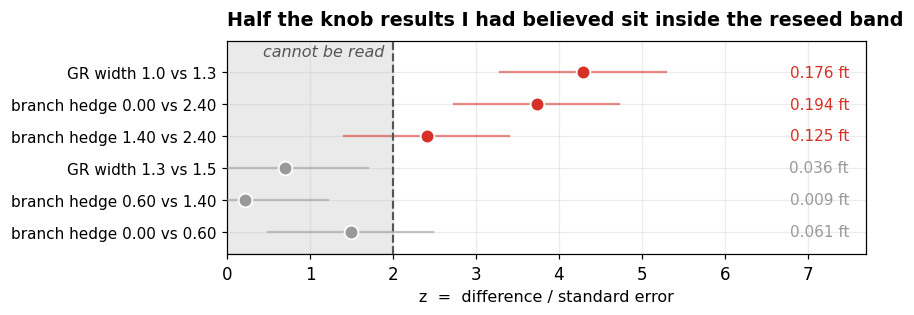

In [2]:
# The six comparisons from the table above, drawn as distances from the bar.
# Sized for Kaggle's ~730px body: 8.1in wide, fonts >=10.
import numpy as np, matplotlib.pyplot as plt
ROWS = [("branch hedge 0.00 vs 0.60", 0.061, 0.041), ("branch hedge 0.60 vs 1.40", 0.009, 0.041),
        ("GR width 1.3 vs 1.5", 0.036, 0.052),        ("branch hedge 1.40 vs 2.40", 0.125, 0.052),
        ("branch hedge 0.00 vs 2.40", 0.194, 0.052),  ("GR width 1.0 vs 1.3", 0.176, 0.041)]
fig, ax = plt.subplots(figsize=(8.1, 3.0))
ax.axvspan(0, 2, color="#bbbbbb", alpha=.30, zorder=1)
for i, (lab, diff, se) in enumerate(ROWS):
    z = diff/se; real = z >= 2
    c = "#d73027" if real else "#999999"
    ax.plot([max(z-1, 0), z+1], [i, i], color=c, lw=1.5, alpha=.55, zorder=3)
    ax.plot([z], [i], "o", color=c, ms=9, zorder=5, markeredgecolor="white", markeredgewidth=1.2)
    ax.text(7.5, i, f"{diff:.3f} ft", va="center", ha="right", fontsize=10, color=c)
ax.axvline(2, color="#555", ls="--", lw=1.4, zorder=4)
ax.text(1.9, 5.5, "cannot be read", ha="right", fontsize=10.5, color="#555", style="italic")
ax.set_yticks(range(len(ROWS))); ax.set_yticklabels([r[0] for r in ROWS], fontsize=10)
ax.set_xlim(0, 7.7); ax.set_ylim(-.7, 6.0)
ax.set_xlabel("z  =  difference / standard error", fontsize=10.5)
ax.set_title("Half the knob results I had believed sit inside the reseed band",
             loc="left", fontsize=12.5, fontweight="bold", pad=10)
plt.tight_layout(); plt.show()


<a id="forum"></a>
## It does not settle the forum argument

souldrive ([728477](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/728477)) fits another team's five published CV and leaderboard pairs at r = 0.999 and slope 1.01, and concludes the board is a precise ruler whose apparent noise is really the submitter's own nondeterminism. radiant-allomancer ([724932](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/724932)) reports the reverse across eight real submissions: an out-of-fold score with whole wells held out improved from 8.248 to 7.623 while the public score moved the wrong way, 6.675 to 6.924, at a rank correlation of −0.243.

By my own bar that public move of 0.249 ft is not noise, at least not noise the size of mine. Whether it is noise the size of theirs is the thing neither of us can say. Settling it needs radiant-allomancer's own rerun spread, four or five unchanged resubmissions of a single kernel, and I have not seen one for that pipeline.

So the rule is the title. Before you believe a lever, resubmit something unchanged a few times and find out what your own board actually resolves.



<a id="newhere"></a>
## New here

Sections 2 to 5 are the map. Part of the error is recoverable: a per-well offset plus a piecewise dip, which you read by matching the well's gamma-ray against the reference typewell logged nearby. Part of it is not. The rock is rhythmically bedded, so the gamma-ray lines up at two stratigraphic positions about one bundle apart, roughly &plusmn;15&nbsp;ft either side of the hedge, and the choice between them is close to a coin flip, and the worst tenth of wells carry about 40 per cent of the squared error. Section 9 is a small harness you point at your own predictions to read your own ceiling and your own leave-group-out result.

Section 10 credits work that is not mine: pilkwang on the reseed spread this opening leads with, Malyshev Danil on the per-well datum's identifiability and on what neighbouring wells cannot lend you, souldrive on the structural surface, radiant-allomancer on whole-well recurrent models. My two earlier retractions are still in section 11.


## Contents

**The measurement this version leads with**
- [What a foot is worth here](#stakes)
- [The measurement](#measurement)
- [Turning it on my own work](#turning)
- [It does not settle the forum argument](#forum)
- [New here](#newhere)

**The map, unchanged from earlier versions**
1. [The task in one paragraph](#1)
2. [The floor: a calibrated oracle ladder](#2)
3. [The error collapses to offset plus a piecewise dip](#3)
4. [Reading the dip: GR-to-typewell matching has a quality ceiling](#4)
5. [The irreducible tail: a bimodal datum](#5)
   - [5a. The legal route: heel-calibration](#5c)
   - [5b. How big is the human noise floor?](#5d)
6. [The leave-field-out result, in proportion](#6)
   - [6a. Two community claims, run through the ruler](#6b)
7. [Traps that look like progress](#7)
8. [What to do if you are stuck near the cluster](#8)
9. [Fork the ruler, not the model](#9)
10. [What is not mine](#10)
11. [Two corrections to earlier versions](#11)
12. [Design choices and limitations](#12)
13. [References and a question for you](#13)

This is a diagnostic, not a submission. It scores nothing, runs end to end on public data (the competition's own files plus the one public dataset attached for [&sect;5d](#5d)), and is built to be forked.


<a id="setup"></a>
### Setup

Everything below runs on **public data only** — the competition's own files, plus one public dataset I attached in §5d — so a fork runs end-to-end with no private artefacts. Seeded; a 250-well subsample keeps the run to a few minutes — the full 773 wells give the same picture, and §6b's neighbour ladder does sweep the full set once.

In [3]:
import os, glob, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.ensemble import HistGradientBoostingRegressor as HGB
from scipy.spatial import cKDTree
warnings.filterwarnings("ignore")

SEED = 42; np.random.seed(SEED)
N_WELLS = 250                         # subsample for runtime; full 773 ~ same result
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})
# colorblind-safe (Okabe–Ito)
C = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00",
         grey="#999999", purple="#CC79A7")

def find_train():
    for c in ["/kaggle/input/competitions/rogii-wellbore-geology-prediction/train",
              "/kaggle/input/rogii-wellbore-geology-prediction/train", "data/train"]:
        if os.path.isdir(c): return c
    g = glob.glob("/kaggle/input/**/train", recursive=True)   # robust mount resolve
    return g[0] if g else "data/train"

TRAIN = find_train()
files = sorted(glob.glob(f"{TRAIN}/*__horizontal_well.csv"))
rng = np.random.RandomState(SEED)
files = [files[i] for i in rng.permutation(len(files))[:N_WELLS]]
rmse = lambda a: float(np.sqrt(np.mean(np.asarray(a, float) ** 2)))
print(f"train dir: {TRAIN}")
print(f"wells in sample: {len(files)} / {len(glob.glob(f'{TRAIN}/*__horizontal_well.csv'))}")

train dir: /kaggle/input/competitions/rogii-wellbore-geology-prediction/train
wells in sample: 250 / 773


<a id="1"></a>
## 1. The task in one paragraph

Each well is a horizontal trajectory with logs `MD, X, Y, Z, GR`, a known `TVT_input` up to a prediction-start point, and a vertical **typewell** (GR vs TVT). We predict `TVT` on the hidden eval tail; on the eval rows `X/Y/Z` are known and `TVT` is hidden. The metric is pooled row-wise RMSE over the eval rows.

A few community-established facts fix the problem; I take them as given.

*Fact one: the target reduces to a surface.* &nbsp; The first is that the target reduces to a surface. `TVT = ANCC(surface) − Z + b_well`, with `b_well` constant per well (std 0.0064&nbsp;ft). `Z` is known on the tail and the offset is pinned by the heel, so predicting `TVT` is reading the formation surface along the lateral. One caution about reading that identity through a correlation: pooled across all wells `ANCC` and `TVT` correlate at about −0.94, which a couple of EDAs have read as a near-leaky column, but within a single well the same correlation flips sign to roughly +0.26. The sign flip is Simpson's paradox — the pooled number is dominated by the between-well offsets, not the within-well relationship — so the strong pooled correlation is not a shortcut to exploit. The identity above, with `b_well` pinned per well, is the honest way to use it.

*Fact two: six columns, one surface.* &nbsp; The second is that the six formation columns are not six surfaces. franticXu showed that `ANCC, ASTNU, ASTNL, EGFDU, EGFDL, BUDA` collapse to one base surface plus five constant offsets — one degree of freedom, with layer thickness std under 0.01&nbsp;ft along each well. They are derived from the typewell's TVT boundaries (in 97.5% of wells the typewell thickness equals the horizontal-well thickness), not measured 3D surfaces. One point that trips people up: `TVT` here is a *cumulative* vertical distance, like TVD, rather than the thickness of a single layer. The test wells ship without these formation columns, so they have to be reconstructed, and a few wells have a truncated or absent ANCC.

*Fact three: what "matching" even means.* &nbsp; The third is what "matching" even means. Tabish's breakdown puts it cleanly: the typewell is a GR-vs-TVT lookup, and you read your stratigraphic position by matching the horizontal well's GR trace against it. The layers run roughly parallel, and many wells share subsequences of a master typewell sequence. So the target is not one number; it is a piecewise dip, what Tabish calls "parallel jagged lines."

The rest of the notebook maps where that surface is recoverable from the data and where it is not.

In [4]:
# load eval-row truth + geometry once; reused throughout
def load(f):
    hw = pd.read_csv(f)
    tvi, tv = hw["TVT_input"].to_numpy(float), hw["TVT"].to_numpy(float)
    Z, MD, GR = hw["Z"].to_numpy(float), hw["MD"].to_numpy(float), hw["GR"].to_numpy(float)
    X, Y = hw["X"].to_numpy(float), hw["Y"].to_numpy(float)
    ev = np.isnan(tvi) & np.isfinite(tv); ei = np.flatnonzero(ev)
    kn = np.flatnonzero(~np.isnan(tvi))
    if len(ei) < 50 or len(kn) < 50: return None
    li = kn[-1]
    s = (MD[ei] - MD[li]) / max(MD[-1] - MD[li], 1e-6)        # normalized tail position 0..1
    return dict(wid=os.path.basename(f)[:8], file=f, true=tv[ei], s=s, Z=Z[ei], MD=MD[ei],
                last=tvi[li], surf=tv[ei] + Z[ei], X=X, Y=Y, GR=GR, ei=ei, kn=kn, li=li,
                tvi=tvi, hwZ=Z, hwMD=MD)
W = [w for w in (load(f) for f in files) if w is not None]
print(f"usable wells: {len(W)}")

usable wells: 250


<a id="2"></a>
## 2. The floor: a calibrated oracle ladder

Before chasing a better model, ask the cheaper question: if you already knew the answer, what is the best each modeling assumption could do? Each rung below uses the *true* tail to fit the simplest possible shape, then reports its pooled RMSE. That is a ceiling no model *restricted to that shape* can beat — and the ladder turns out to be anchored to the real board, which is the point.

- **flat** — carry the last known TVT (the only fully-legal rung here; a sanity floor).
- **constant** — the best single per-well offset.
- **line** — the best per-well straight line vs measured depth.
- **smooth** — a robust degree-6 fit (captures the wiggle too).

In [5]:
def robfit(s, y, deg):
    if len(s) < deg + 2: return y.copy()
    c = np.polyfit(s, y, deg)
    for _ in range(3):
        r = y - np.polyval(c, s); sc = np.median(np.abs(r)) * 1.4826 + 1e-6
        c = np.polyfit(s, y, deg, w=1.0 / (1.0 + (r / (2 * sc)) ** 2))
    return np.polyval(c, s)

E = {k: [] for k in ["flat", "constant", "line", "smooth"]}
for w in W:
    t, s = w["true"], w["s"]
    E["flat"].append(t - w["last"])
    E["constant"].append(t - t.mean())
    E["line"].append(t - np.polyval(np.polyfit(s, t, 1), s))
    E["smooth"].append(t - robfit(s, t, 6))
ladder = {k: rmse(np.concatenate(v)) for k, v in E.items()}
_tbl = pd.DataFrame({"Oracle RMSE (ft)": [ladder[k] for k in ["flat","constant","line","smooth"]],
                     "What it captures": ["carry the last known value", "best single offset", "best straight line", "adds the wiggle"]},
                    index=["flat (legal)", "constant offset", "per-well line", "smooth (deg-6)"])
_tbl.index.name = "Assumption (oracle)"

# per-well figures used later (measured here, not borrowed):
line_w   = np.array([rmse(e) for e in E["line"]])      # per-well RMSE under the line oracle
smooth_w = np.array([rmse(e) for e in E["smooth"]])    # ...and under the smooth oracle
sse_w    = np.array([float(np.sum(e**2)) for e in E["smooth"]])
_ord = np.argsort(sse_w)[::-1]; _k10 = max(1, len(sse_w)//10)
worst10_share = sse_w[_ord[:_k10]].sum() / sse_w.sum()
print(f"wells already under 5 ft per-well:  line oracle {np.mean(line_w<5):.0%}   smooth oracle {np.mean(smooth_w<5):.0%}")
print(f"worst 10% of wells carry {worst10_share:.0%} of the smooth-oracle squared error  (the tail; see §5)")
(_tbl.style.format({"Oracle RMSE (ft)": "{:.2f}"})
     .background_gradient(subset=["Oracle RMSE (ft)"], cmap="Greens_r")
     .set_table_styles([{"selector": "th", "props": [("font-size", "13px")]}])
     .set_properties(**{"font-size": "13px"}))

wells already under 5 ft per-well:  line oracle 43%   smooth oracle 96%
worst 10% of wells carry 40% of the smooth-oracle squared error  (the tail; see §5)


,Oracle RMSE (ft),What it captures
Assumption (oracle),,
flat (legal),16.61,carry the last known value
constant offset,9.07,best single offset
per-well line,6.59,best straight line
smooth (deg-6),3.00,adds the wiggle


**Table 1 — the oracle ladder.** Pooled RMSE over 250 train wells; each rung fits the simplest shape to the *true* tail, so it is an unreachable ceiling *for that assumption*, not a model score.

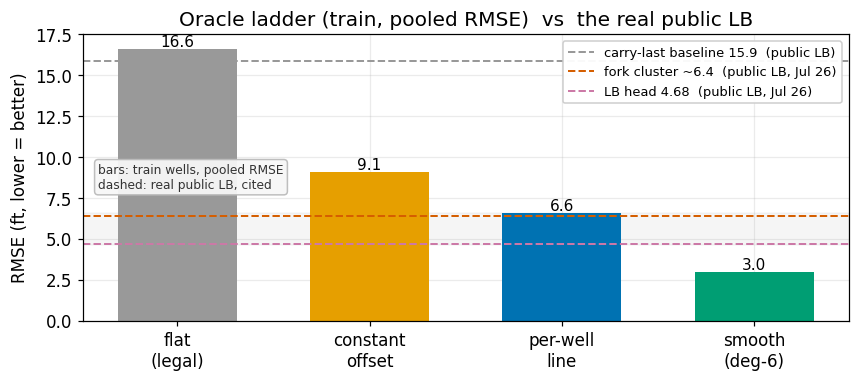

In [6]:
fig, ax = plt.subplots(figsize=(7.8, 3.6))
names = ["flat\n(legal)", "constant\noffset", "per-well\nline", "smooth\n(deg-6)"]
vals = [ladder[k] for k in ["flat", "constant", "line", "smooth"]]
bars = ax.bar(names, vals, color=[C["grey"], C["orange"], C["blue"], C["green"]], width=.62)
for b, v in zip(bars, vals): ax.text(b.get_x()+b.get_width()/2, v+.15, f"{v:.1f}", ha="center", fontsize=10)
# reference lines — CITED from the REAL public LB (honestly scored on the hidden wells), NOT recomputed here.
ax.axhspan(4.6, 6.6, color="#cccccc", alpha=.18, zorder=0)
ax.axhline(15.883, ls="--", lw=1.3, color=C["grey"],   label="carry-last baseline 15.9  (public LB)")
ax.axhline(6.40,   ls="--", lw=1.3, color=C["red"],    label="fork cluster ~6.4  (public LB, Jul 26)")
ax.axhline(4.68,   ls="--", lw=1.3, color=C["purple"], label="LB head 4.68  (public LB, Jul 26)")
ax.legend(loc="upper right", fontsize=8.5, framealpha=.95)
ax.text(0.02, 0.55, "bars: train wells, pooled RMSE\ndashed: real public LB, cited",
        transform=ax.transAxes, va="top", ha="left", fontsize=8, color="#333",
        bbox=dict(boxstyle="round,pad=0.3", fc="#f7f7f7", ec="#bbbbbb", alpha=.95))
ax.set_ylabel("RMSE (ft, lower = better)"); ax.set_ylim(0, 17.5)
ax.set_title("Oracle ladder (train, pooled RMSE)  vs  the real public LB")
plt.tight_layout(); plt.show()

**Read it like this.** Carrying the last value is hopeless (~16). The live carry-last baseline scores **15.883**. Same procedure, different well sets — my flat oracle on a 250-well train sample, the baseline on the hidden public wells — so I read the agreement as a sanity check that my ladder is on the board's scale, not as proof of anything finer.

From there it descends. One offset per well already cuts it to ~9. The per-well **line** oracle (~6.6) now sits *above* the fork cluster (about 6.3 to 6.5), and that is a change since the earlier versions of this notebook, when the cluster sat a full point worse than it. The public frontier has moved past what a per-well straight line can do, so the forks are no longer just capturing the offset and the dominant slope; some of the wiggle and the dip changes are in there too. The board **heads** (4.68 to 5.06 on 26 July) sit far below the line oracle. The smooth oracle at ~3.0 is a train-side ceiling rather than a board fact: it needs the truth to fit, so it bounds what a shape could represent, not what anyone can recover.

One fence, so the two kinds of marker are not confused. The **bars** are train-fit ceilings — pooled RMSE on 250 train wells, each unreachable for its assumption because each needed the truth to fit. The **dashed lines** are live, honestly-scored public-LB markers. Different categories, same RMSE scale. The ordering is what carries the argument: forks near the line oracle, heads reaching into the wiggle, recoverable structure still below. The next sections are about what "reaching into the wiggle" requires.

One more anchor, added after wharekawa reproduced this ladder in the discussion to the last digit: on the full 773 wells it reads 9.04 / 6.70 / 3.05 with flat at 15.91 — same shape, same story. A reproduction is the strongest check a harness can get.

<a id="3"></a>
## 3. The error collapses to offset plus a piecewise dip

Take the surface along each lateral, `ANCC = TVT + Z`, and fit a straight line in measured depth. How much is left?

In [7]:
lin_r2, wiggle, slopes = [], [], []
for w in W:
    surf, s = w["surf"], w["s"]
    lin = np.polyval(np.polyfit(s, surf, 1), s)
    ss_res = np.sum((surf - lin) ** 2); ss_tot = np.sum((surf - surf.mean()) ** 2)
    lin_r2.append(1 - ss_res / max(ss_tot, 1e-9))
    wiggle.append(np.std(surf - lin))
    slopes.append(np.polyfit(w["s"], w["true"] - w["last"], 1)[0])   # drift slope vs flat baseline
print(f"surface linear-fit R^2 : median {np.median(lin_r2):.3f}   ({np.mean(np.array(lin_r2)>0.9):.0%} of wells > 0.90)")
print(f"residual wiggle (std)  : median {np.median(wiggle):.2f} ft")

surface linear-fit R^2 : median 0.992   (97% of wells > 0.90)
residual wiggle (std)  : median 3.92 ft


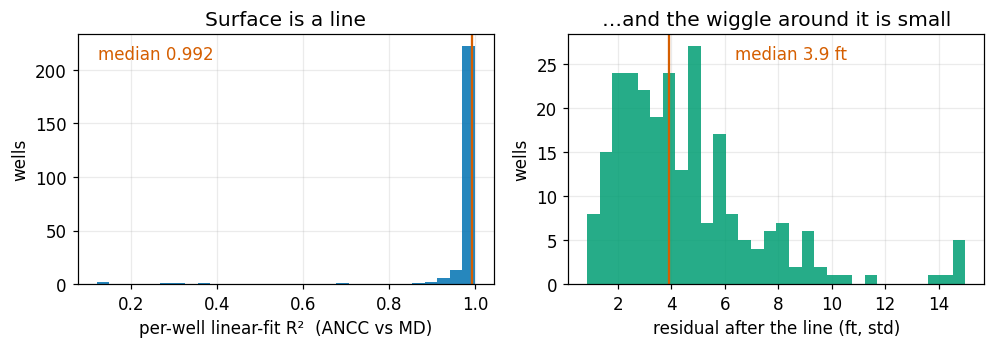

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.3))
ax[0].hist(lin_r2, bins=30, color=C["blue"], alpha=.85)
ax[0].axvline(np.median(lin_r2), color=C["red"], lw=1.5)
ax[0].set_title("Surface is a line"); ax[0].set_xlabel("per-well linear-fit R²  (ANCC vs MD)")
ax[0].set_ylabel("wells"); ax[0].text(.05,.9,f"median {np.median(lin_r2):.3f}",transform=ax[0].transAxes,color=C["red"])
ax[1].hist(np.clip(wiggle,0,15), bins=30, color=C["green"], alpha=.85)
ax[1].axvline(np.median(wiggle), color=C["red"], lw=1.5)
ax[1].set_title("…and the wiggle around it is small"); ax[1].set_xlabel("residual after the line (ft, std)")
ax[1].set_ylabel("wells"); ax[1].text(.4,.9,f"median {np.median(wiggle):.1f} ft",transform=ax[1].transAxes,color=C["red"])
plt.tight_layout(); plt.show()

For the typical well the surface is a straight line to within a few feet over the whole lateral: median R² ≈ 0.99. The exceptions are the faulted minority, with steps of 15–30&nbsp;ft, and they are exactly the piecewise tail §5 is about, so don't let the median hide them. The line claim is about the middle of the distribution, not its ends.

That collapses the problem, but not down to a single number. Once the per-well offset is set by the heel, what is left is the dip, and the dip varies along the well. Following Tabish, `TVT + Z` and the layers are piecewise continuous linear functions, the "parallel jagged lines": a dominant slope plus the break points where it changes. The offset is pinned by the heel; the dip and its breaks are what you have to read. The breaks come from the same sub-seismic faults — they belong to the hard tail (§5), not to noise you should smooth away.

This is the recoverable part of the map. The offset plus the dominant slope is what the public fork cluster has captured; the heads pull in some of the dip changes and the wiggle on top. The cell in §2 prints how many wells already sit under 5&nbsp;ft per-well from a clean smooth fit — a sizable chunk, which is why the room to improve is on the median wells. So the gap below the cluster is a matching problem: read the dip off the typewell well enough, on more wells. The next section is about that match.

<a id="4"></a>
## 4. Reading the dip: GR-to-typewell matching has a quality ceiling

Geosteering works because the gamma-ray log fingerprints the rock: match the well's `GR` to the typewell's `GR`-vs-`TVT` profile and you know your vertical position. The question is how far that match gets you, and what the bottleneck is.

First, the legality, because it decides what "matching" is even allowed to use. Settled in the Tiago thread: using the full per-well GR trace, including rows ahead of the eval row (the within-well "look-ahead"), is legal. This is post-drilling analysis, and the rule there was that everything in the data we are given is fair game unless explicitly forbidden. So matching your whole GR trace against the typewell, which is what the top solvers do, is fair.

And it reaches further than I gave it credit for. Tucker Arrants described reaching about 5 pooled per-row using per-well data only — no cross-well features, no spatial structure, no external tops. I am reading that off his post rather than a shared notebook, and it is a train-CV figure rather than a leaderboard score, so I will not lean on it harder than that. But even as one data point it scopes the task: for at least the front of the field, the live lever is per-well GR-matching quality, and the cross-field slope transfer I spent a section proving hard (§6) is not required to get there.

So why doesn't the match trivially nail it? There is a real degeneracy, and I measure it with a **shift scan**. For each well, slide a candidate vertical offset `dz` and ask where the GR-misfit against the typewell is smallest, under three calibrations of the GR gain and offset:

- **oracle** — calibrate at the *true* TVT (illegal; an upper bound on what GR knows).
- **legal** — calibrate at a legitimate flat-surface guess (`last_known + (Z_heel − Z)`, known quantities only).
- **shuffle** — calibrate at a shuffled TVT (a random control).

In [9]:
GRID = np.arange(-20.0, 20.01, 0.5)            # candidate vertical shifts dz; 0 = the truth
def twgr(tvt, tv, tg): return np.interp(tvt, tv, tg, left=tg[0], right=tg[-1])
def load_tw(w):
    twf = w["file"].replace("__horizontal_well.csv", "__typewell.csv")
    if not os.path.exists(twf): return None, None
    tw = pd.read_csv(twf); tv = tw["TVT"].to_numpy(float); tg = tw["GR"].to_numpy(float)
    o = np.argsort(tv); tv, tg = tv[o], tg[o]; _, ix = np.unique(tv, return_index=True)
    return tv[ix], tg[ix]
def misfit_curve(gr, true, calib_tvt, tv, tg):
    v = np.isfinite(gr)
    tgt = twgr(calib_tvt, tv, tg)
    coef, *_ = np.linalg.lstsq(np.vstack([gr[v], np.ones(v.sum())]).T, tgt[v], rcond=None)  # fit gain/offset
    cal = gr * coef[0] + coef[1]
    return np.array([np.mean((cal[v] - twgr(true + dz, tv, tg)[v]) ** 2) for dz in GRID])
def argmin_dz(gr, true, calib_tvt, tv, tg):
    return abs(GRID[int(np.argmin(misfit_curve(gr, true, calib_tvt, tv, tg)))])

orc, leg, shf, lat_span, tw_span, worst_idx = [], [], [], [], [], []
rs = np.random.RandomState(SEED)
for wi, w in enumerate(W):
    tv, tg = load_tw(w)
    if tv is None: continue
    gr = pd.Series(w["GR"][w["ei"]]).interpolate(limit_direction="both").to_numpy()
    true = w["true"]
    if np.sum(np.isfinite(gr)) < 20 or len(tv) < 10 or np.std(gr) < 1e-6: continue
    legal = w["last"] + (w["hwZ"][w["li"]] - w["Z"])          # legal flat-surface guess; Z is known on the tail (§1)
    orc.append(argmin_dz(gr, true, true, tv, tg))
    leg.append(argmin_dz(gr, true, legal, tv, tg))
    shf.append(argmin_dz(gr, true, true[rs.permutation(len(true))], tv, tg))
    lat_span.append(np.percentile(true,97)-np.percentile(true,3)); tw_span.append(np.percentile(tv,97)-np.percentile(tv,3))
    worst_idx.append(wi)
orc, leg, shf = map(np.array, (orc, leg, shf))
from IPython.display import display
_deg = pd.DataFrame({"median |dz| from truth (ft)": [np.median(orc), np.median(leg), np.median(shf)],
                     "localized within 2 ft": [np.mean(orc<=2), np.mean(leg<=2), np.mean(shf<=2)]},
                    index=["oracle (illegal)", "legal (public)", "shuffle (control)"])
_deg.index.name = "GR calibration"
display(_deg.style.format({"median |dz| from truth (ft)": "{:.2f}", "localized within 2 ft": "{:.0%}"})
        .set_table_styles([{"selector": "th", "props": [("font-size", "13px")]}])
     .set_properties(**{"font-size": "13px"})
     .apply(lambda r: ["background-color:#fde7e0"]*len(r) if r.name == "legal (public)" else [""]*len(r), axis=1))
print(f"context: the answer moves ~{np.median(lat_span):.0f} ft through a ~{np.median(tw_span):.0f} ft typewell column")

,median |dz| from truth (ft),localized within 2 ft
GR calibration,,
oracle (illegal),0.00,82%
legal (public),13.00,8%
shuffle (control),9.50,17%


context: the answer moves ~24 ft through a ~857 ft typewell column


**Table 2 — the calibration degeneracy.** Median |dz| from the true surface and the fraction of wells localized within 2 ft, under three GR calibrations; the legal row (highlighted) falls **below** the random-shuffle control, 8% against 17% — the explicit gain/offset fit localizes only when calibrated at the truth, and fitting it in the wrong place is worse than not fitting it at all.

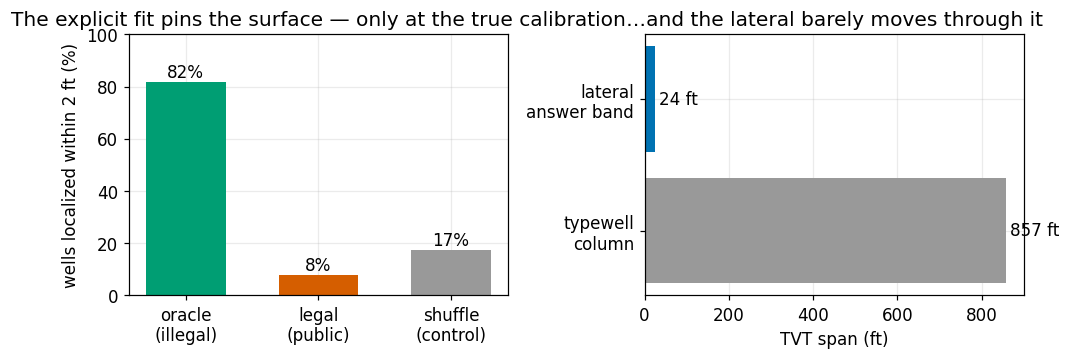

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.4))
labs = ["oracle\n(illegal)", "legal\n(public)", "shuffle\n(control)"]
frac = [np.mean(orc<=2), np.mean(leg<=2), np.mean(shf<=2)]
bars = ax[0].bar(labs, [f*100 for f in frac], color=[C["green"], C["red"], C["grey"]], width=.6)
for b, f in zip(bars, frac): ax[0].text(b.get_x()+b.get_width()/2, f*100+2, f"{f:.0%}", ha="center")
ax[0].set_ylabel("wells localized within 2 ft (%)"); ax[0].set_ylim(0, 100)
ax[0].set_title("The explicit fit pins the surface — only at the true calibration")
ax[1].barh(["typewell\ncolumn", "lateral\nanswer band"], [np.median(tw_span), np.median(lat_span)],
           color=[C["grey"], C["blue"]])
for i, v in enumerate([np.median(tw_span), np.median(lat_span)]): ax[1].text(v+10, i, f"{v:.0f} ft", va="center")
ax[1].set_xlabel("TVT span (ft)"); ax[1].set_title("…and the lateral barely moves through it")
plt.tight_layout(); plt.show()

Read the left panel. With the **oracle** calibration the GR-misfit minimum lands on the true surface in about 82% of wells (median offset 0 ft). The gamma-ray tracks lithology, as it should. But fit the same explicit gain/offset at any **legal** position and that skill collapses: only ~8% of wells localize, against 17% for the random-shuffle control, with the minimum wandering a dozen feet. The control wins because shuffling degenerates into fitting the mean, which is less biased than fitting hard at a wrong position. The right panel says why this particular fit struggles. The answer moves through about 24&nbsp;ft while the typewell spans hundreds, so the lateral never travels far enough vertically to pin the gain and offset from the data alone.

*The ceiling, measured with the most generous illegal fit.* &nbsp; To put a hard number on the absolute-positioning ceiling, I ran the most generous *illegal* version of GR matching there is — a separate train-side recompute, not a cell in this notebook: an oracle registration that sees the *true* eval gamma ray and grid-searches the best global offset and slope of the TVT line to match the typewell shape. Unlike the §2 line oracle, which fits the line to the true TVT, this one fits only the GR shape, and on a 200-well sample it scores about 31&nbsp;ft RMSE against ~17 for carrying the last value flat, recovering the eval slope at essentially zero correlation (−0.00). Letting GR alone choose the absolute position hurts, because GR(TVT) repeats: the best global match points confidently at a wrong depth. That is the same self-similarity §5 turns into the bimodal datum, and it is why the legal route in §5c pins the offset at the heel rather than fitting it globally. What GR carries is relative and coarse, best read sequentially against the typewell with the offset already pinned: that is the ~10 a particle filter reaches and the ~5 a better matcher reaches, not a global fit.

*The correction, in one pass.* &nbsp; So the correction to my earlier claim, in one pass: "GR cannot pin the slope, and that is a property of the data" was too strong. The confound is a property of *this explicit-calibration method* — the naive gain/offset fit is confounded with position — and my tracker's ~10&nbsp;ft (~10.9 under leave-whole-field-out) is *that tracker's* limit under one hard split, not a GR ceiling. GR carries real coarse signal: a particle filter takes my selector from the ~16 floor down to ~10 with it, and Tucker's ~5 per-well, as I read it, says a sequential matcher that uses the typewell directly pulls more of the dip and wiggle out of the same data. The gap from my ~10 to ~5 is alignment headroom, not an information wall.

*Which aligner actually gets further: a tournament.* &nbsp; Which sequential matchers actually get further? I ran three head-to-head on a fixed protocol — the same 150 train wells, the same grouped folds, each aligner's output fed to the same downstream model — and scored by the honest marginal delta it added once the confounds were stripped (separate train-side runs, not cells here). Only one survived. A windowed, shape-matching particle filter earned −0.18&nbsp;±&nbsp;0.04&nbsp;ft across five seeds, negative on all five. DTW with calibration was a wash overall and 1.2&nbsp;ft *worse* than flat on the wells with no real offset — it invents movement where there is none. Windowed cross-correlation made things slightly worse the moment its alignment features were stacked on two plain GR scalars. And the sharpest part is *where* the particle filter's value lives: not in the TVT it proposes (its median move is ~0.1&nbsp;ft, essentially staying home) but in its uncertainty — the posterior spread correlates with the actual error at +0.23. Stacked on a model as features, GR alignment earned its keep as a per-row trust gate, deciding when to believe the anchor, not as a predictor — the predicting in my own pipeline stayed with the bounded matcher (§8). FOYSAL's working note reaches the same boundary from the solver side: un-gated GR matching picks confident wrong depths, and the guard is where the value is.

*One practical lever before §5.* &nbsp; One practical lever before the next section, from the Problem Breakdown thread: the GR sensor rotates as the tool turns in the hole (Shrey spotted it, Tabish hosted the breakdown), and an FFT of the GR shows the rotation frequency. MY0705's point is that you can use it to denoise the trace before matching, for cleaner input and better alignment.

<a id="5"></a>
## 5. The irreducible tail: a bimodal datum

If the recoverable part is offset plus dip read off the typewell, the irreducible part is where the typewell stops telling you the truth. This is the piece I think matters most.

*The geology, from souldrive.* &nbsp; The geology comes from souldrive, whose post laid it out (and who, I'll note, publicly endorsed the first version of this notebook — credit due both ways). The Eagle Ford is rhythmically bedded: Milankovitch orbital cyclicity drives limestone–marl couplets that repeat on a ~15–25&nbsp;ft scale. Because the bedding repeats, the horizontal GR can line up with the typewell at two stratigraphic positions about one bundle apart. The datum becomes bimodal, roughly ±15&nbsp;ft, and on a truly ambiguous well it is close to a coin-flip which mode is real. A minority of wells add their own version of this through sub-seismic faults, 15–30&nbsp;ft steps.

*The same object, measured from the data side.* &nbsp; I came at the same object from the other side, on public train so a forker can reproduce it. Fit the smooth oracle per well and sort by squared error: the worst decile carries close to 40% of the total (the cell prints the exact figure), and my selector's own out-of-fold bias puts the same minority sharper still — the 63 of 355 wells with per-well bias over 8&nbsp;ft carry 73% of the error (an offline aggregate, not a cell here). On those worst wells, the §4 shift scan under the *oracle* calibration — the one that localizes 82% of normal wells — shows the GR misfit at the true TVT flat, or slightly worse than a match one bundle away. With the calibration that works elsewhere, that flat misfit is the data being ambiguous, not the fit failing: the typewell cannot tell the two positions apart.

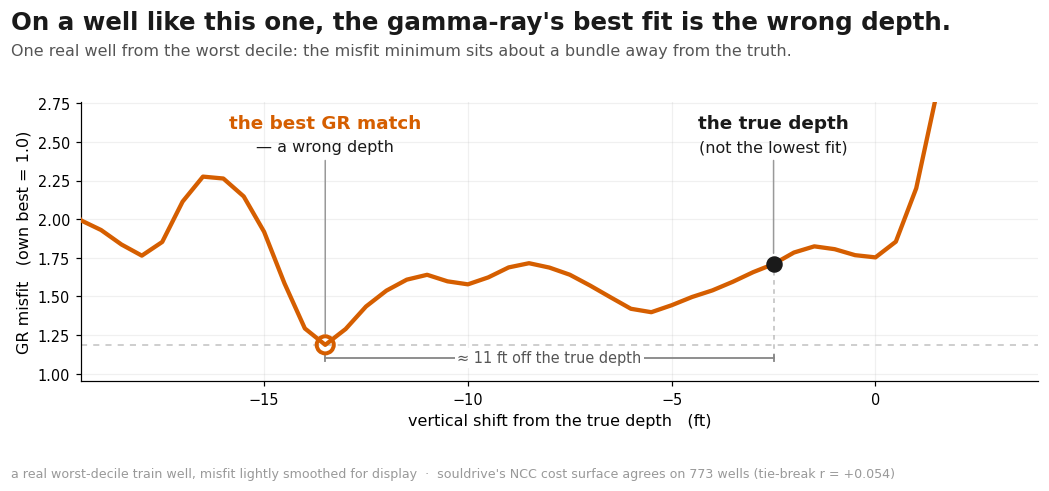

In [11]:
# ---- one real worst-decile train well: the gamma-ray's best fit lands at the WRONG depth ----
import os, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt

def _draw_hero():
    def _train():
        for c in ["/kaggle/input/competitions/rogii-wellbore-geology-prediction/train",
                  "/kaggle/input/rogii-wellbore-geology-prediction/train", "data/train"]:
            if os.path.isdir(c): return c
        g = glob.glob("/kaggle/input/**/train", recursive=True); return g[0] if g else "data/train"
    T = _train()
    G = np.arange(-20.0, 20.01, 0.5); TR = np.abs(G) <= 2.5
    Cn = dict(red="#D55E00", ink="#1a1a1a", grey="#999999")
    def rfit(s, y, d=6):
        if len(s) < d+2: return y.copy()
        c = np.polyfit(s, y, d)
        for _ in range(3):
            r = y - np.polyval(c, s); sc = np.median(np.abs(r))*1.4826 + 1e-6
            c = np.polyfit(s, y, d, w=1.0/(1.0+(r/(2*sc))**2))
        return np.polyval(c, s)
    def sm(a, k=5): return pd.Series(a).rolling(k, center=True, min_periods=1).mean().to_numpy()
    def mis(gr, true, tv, tg):
        v = np.isfinite(gr)
        if v.sum() < 20: return None
        tgt = np.interp(true, tv, tg, left=tg[0], right=tg[-1])
        coef, *_ = np.linalg.lstsq(np.vstack([gr[v], np.ones(v.sum())]).T, tgt[v], rcond=None)
        cal = gr*coef[0] + coef[1]
        return np.array([np.mean((cal[v]-np.interp(true+dz, tv, tg, left=tg[0], right=tg[-1])[v])**2) for dz in G])
    fs = sorted(glob.glob(f"{T}/*__horizontal_well.csv"))
    rng = np.random.RandomState(42); fs = [fs[i] for i in rng.permutation(len(fs))[:160]]
    Ws = []
    for f in fs:
        try: hw = pd.read_csv(f, usecols=["MD","GR","TVT","TVT_input"])
        except Exception: continue
        tvi = hw["TVT_input"].to_numpy(float); tv = hw["TVT"].to_numpy(float)
        GR = hw["GR"].to_numpy(float); MD = hw["MD"].to_numpy(float)
        ei = np.flatnonzero(np.isnan(tvi) & np.isfinite(tv)); kn = np.flatnonzero(~np.isnan(tvi))
        if len(ei) < 50 or len(kn) < 50: continue
        twf = f.replace("__horizontal_well.csv","__typewell.csv")
        if not os.path.exists(twf): continue
        tw = pd.read_csv(twf); ttv = tw["TVT"].to_numpy(float); ttg = tw["GR"].to_numpy(float)
        o = np.argsort(ttv); ttv, ttg = ttv[o], ttg[o]; _, ix = np.unique(ttv, return_index=True); ttv, ttg = ttv[ix], ttg[ix]
        s = (MD[ei]-MD[kn[-1]])/max(MD[-1]-MD[kn[-1]], 1e-6)
        true = tv[ei]; gr = pd.Series(GR[ei]).interpolate(limit_direction="both").to_numpy()
        Ws.append(dict(true=true, gr=gr, tv=ttv, tg=ttg, sse=float(np.sum((true-rfit(s, true, 6))**2))))
    if not Ws: return
    order = np.argsort([w["sse"] for w in Ws])[::-1]
    worst = [Ws[i] for i in order[:max(1, len(Ws)//8)]]
    win = (G>=-18)&(G<=18); cands = []
    for w in worst:
        c = mis(w["gr"], w["true"], w["tv"], w["tg"])
        if c is None: continue
        cn = sm(c/c.min(), 5)
        vt = cn[TR].min(); dzt = G[TR][int(np.argmin(cn[TR]))]
        gi = int(np.argmin(cn)); gdz = G[gi]; gval = cn[gi]
        cands.append(dict(cn=cn, vt=vt, dzt=dzt, gdz=gdz, gval=gval,
                          rough=np.mean(np.abs(np.diff(cn[win], 2))), gap=vt/max(gval,1e-9), peak=cn[win].max()))
    if not cands: return
    good = [c for c in cands if abs(c["gdz"])>=6 and 1.07<=c["gap"]<=1.9 and abs(c["gdz"])<=17 and c["vt"]<1.8 and c["peak"]<4.0]
    if not good: good = [c for c in cands if abs(c["gdz"])>=4 and c["gap"]>=1.04]
    if not good: good = sorted(cands, key=lambda c:-abs(c["gdz"]))[:1]
    good.sort(key=lambda c: c["rough"])
    h = good[0]; dzt, vt, dzd, vd = h["dzt"], h["vt"], h["gdz"], h["gval"]

    fig, ax = plt.subplots(figsize=(9.6, 4.5)); fig.patch.set_facecolor("white"); ax.set_facecolor("white")
    ax.plot(G, h["cn"], color=Cn["red"], lw=2.8, zorder=5, solid_capstyle="round")
    ytop = max(vt+1.05, 2.7); ax.set_ylim(0.95, ytop)
    ax.axhline(vd, color=Cn["grey"], lw=1, ls=(0,(4,4)), alpha=.6, zorder=1)
    lo, hi = sorted([dzt, dzd]); ax.set_xlim(lo-6, hi+6.5)   # frame the two markers, trim dead space
    ax.scatter([dzt],[vt], s=96, color=Cn["ink"], zorder=6)
    ax.scatter([dzd],[vd], s=125, facecolor="none", edgecolor=Cn["red"], linewidth=2.6, zorder=6)
    ysky = ytop - 0.34
    def lab(dz, val, l1, l2, col):
        ax.annotate("", xy=(dz, val+0.05), xytext=(dz, ysky-0.02), arrowprops=dict(arrowstyle="-", color="#999", lw=1))
        ax.text(dz, ysky+0.14, l1, ha="center", va="bottom", fontsize=12, color=col, fontweight="700")
        ax.text(dz, ysky-0.0, l2, ha="center", va="bottom", fontsize=10.5, color=Cn["ink"])
    lab(dzt, vt, "the true depth", "(not the lowest fit)", Cn["ink"])
    lab(dzd, vd, "the best GR match", "— a wrong depth", Cn["red"])
    yb = vd - 0.085
    ax.plot([dzt, dzt], [yb, vt], color="#888", lw=1, ls=(0, (3, 3)), alpha=.55, zorder=2)  # dropline: true-depth point -> the distance brace, so "N ft off" reads as point-to-point
    ax.plot([lo,hi],[yb,yb], color="#888", lw=1.2, zorder=4)
    for xx in (lo,hi): ax.plot([xx,xx],[yb-0.022,yb+0.022], color="#888", lw=1.2, zorder=4)
    ax.text((lo+hi)/2, yb, f"≈ {abs(dzd-dzt):.0f} ft off the true depth", ha="center", va="center",
            fontsize=9.5, color="#555", bbox=dict(facecolor="white", edgecolor="none", pad=1.4), zorder=5)
    ax.set_xlabel("vertical shift from the true depth   (ft)", fontsize=10.5)
    ax.set_ylabel("GR misfit   (own best = 1.0)", fontsize=10.5)
    for sp in ("top","right"): ax.spines[sp].set_visible(False)
    ax.tick_params(labelsize=9.5); ax.grid(alpha=.18)
    fig.suptitle("On a well like this one, the gamma-ray's best fit is the wrong depth.", x=0.012, y=0.965,
                 ha="left", fontsize=16, fontweight="800", color=Cn["ink"])
    fig.text(0.012, 0.875, "One real well from the worst decile: the misfit minimum sits about a bundle away from the truth.",
             ha="left", fontsize=10.5, color="#555")
    fig.text(0.012, 0.022, "a real worst-decile train well, misfit lightly smoothed for display  ·  souldrive's NCC cost surface agrees on 773 wells (tie-break r = +0.054)",
             ha="left", fontsize=8.3, color=Cn["grey"])
    fig.subplots_adjust(left=0.078, right=0.985, top=0.78, bottom=0.215)
    plt.show()

_draw_hero()

That is the irreducible part of the map. The short version of the whole map:

- **Recoverable.** A per-well offset plus a piecewise dip, read by matching the horizontal well's gamma-ray to the typewell. The easier wells get to roughly 3&ndash;5&nbsp;ft per-well this way. The public fork cluster (about 6.3&ndash;6.5 today) has captured the offset and the dominant slope; the heads capture some of the wiggle on top.
- **Irreducible.** The bimodal datum in the figure above, on a minority of wells. The Eagle Ford is rhythmically bedded, so the GR lines up with the typewell at two stratigraphic positions about one bundle apart (roughly &plusmn;15&nbsp;ft), and the truth is close to a coin flip. In my train-side measurements, the worst ~10% of wells carry about 40% of the squared error.


In [12]:
# ---- §5, train-confirmed: where the error concentrates, and why those wells are ambiguous ----
order = np.argsort(sse_w)[::-1]                 # wells worst-first, by smooth-oracle SSE (from §2)
k10   = max(1, len(sse_w)//10)
share = sse_w[order[:k10]].sum() / sse_w.sum()
cum   = np.cumsum(sse_w[order]) / sse_w.sum()   # Lorenz: cumulative share of the error, worst-first
xf    = np.arange(1, len(cum)+1) / len(cum)

# the worst few wells' GR misfit vs a datum shift, under the ORACLE calibration (centred on truth):
worst_misfit = []                               # (well id, misfit / its own min) — the truth is at dz=0
for wi in order:
    if len(worst_misfit) >= 3: break
    w = W[wi]; tv, tg = load_tw(w)
    if tv is None: continue
    gr = pd.Series(w["GR"][w["ei"]]).interpolate(limit_direction="both").to_numpy()
    if np.sum(np.isfinite(gr)) < 20 or len(tv) < 10 or np.std(gr) < 1e-6: continue
    c = misfit_curve(gr, w["true"], w["true"], tv, tg)      # oracle calibration (at the truth)
    worst_misfit.append((w["wid"], c / c.min()))
print(f"worst 10% of wells carry {share:.0%} of the smooth-oracle squared error (train sample of {len(W)} wells)")

worst 10% of wells carry 40% of the smooth-oracle squared error (train sample of 250 wells)


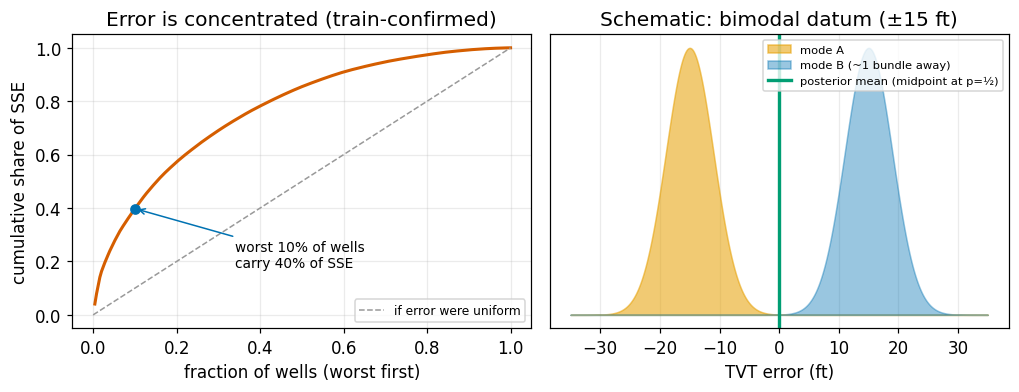

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(9.4, 3.7))

# (a) cumulative-SSE (Lorenz) curve — the concentration, measured on train
ax[0].plot(xf, cum, color=C["red"], lw=2)
ax[0].plot([0,1],[0,1], ls="--", lw=1, color=C["grey"], label="if error were uniform")
ax[0].scatter([0.10],[share], color=C["blue"], zorder=5)
ax[0].annotate(f"worst 10% of wells\ncarry {share:.0%} of SSE", (0.10, share),
               xytext=(0.34, max(share-0.22, 0.12)), fontsize=9,
               arrowprops=dict(arrowstyle="->", color=C["blue"]))
ax[0].set_xlabel("fraction of wells (worst first)"); ax[0].set_ylabel("cumulative share of SSE")
ax[0].set_title("Error is concentrated (train-confirmed)"); ax[0].legend(loc="lower right", fontsize=8)

# (b) schematic of the bimodal datum — an illustration of souldrive's mechanism, NOT a measurement
xx = np.linspace(-35, 35, 400); g = lambda m: np.exp(-0.5*((xx-m)/4.0)**2)
ax[1].fill_between(xx, g(-15), color=C["orange"], alpha=.55, label="mode A")
ax[1].fill_between(xx, g(15),  color=C["blue"],   alpha=.40, label="mode B (~1 bundle away)")
ax[1].axvline(0, color=C["green"], lw=2.2, label="posterior mean (midpoint at p=½)")
ax[1].set_yticks([]); ax[1].set_xlabel("TVT error (ft)")
ax[1].set_title("Schematic: bimodal datum (±15 ft)"); ax[1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout(); plt.show()

*Where a different model earns its keep.* &nbsp; There is a third sign the tail is where the leverage sits: it is the only place a different tree model buys anything. On an older 200-well cross-validation pass, swapping the XGB reference for an LGB+CatBoost blend bought about 0.8&nbsp;ft, winning all four folds, and the gain came off the two heavy-tail folds where XGB was the worst model. Those are directional deltas on a small, stale subset, not board numbers — but the direction is the point: the wells that carry the error are also the only wells where a different model earns its keep.

*What to do about it: the decision theory.* &nbsp; The decision theory is what makes this load-bearing, and pilkwang sharpened it in the comments. On a well with mass `p` at one position and `1−p` at the other a distance `d` apart, the squared-loss-optimal estimate is the posterior mean `p·a + (1−p)·b`, with irreducible risk `p(1−p)d²`; the midpoint I first reached for is just the `p = ½` case. Committing to one mode beats the midpoint only outside `¼ < p < ¾`, while the posterior mean does at least as well as either for every `p` — strictly better than the midpoint whenever `p ≠ ½`, and strictly better than a committed mode for every interior `p`. So the target isn't a binary bimodal flag feeding a fixed midpoint; it's a calibrated `p`, and the estimate leans toward whichever mode `p` favours.

*Where `p` comes from.* &nbsp; And `p` falls out of machinery already on the page: the *relative depth* of the two minima in the §4 shift scan is a log-likelihood ratio between the modes, so a two-position softmax over those depths gives `p` directly. It needs a calibrated temperature, or `p` comes out overconfident — and there is a wrinkle that bites on exactly the hard wells: the GR likelihood there is flat or slightly inverted at the truth, the decoy one bundle away fitting a touch better, so a `p` read straight off the misfit leans toward the wrong mode. The irreducible loss is the variance of the datum; the practical question is how well you estimate `p` before that bias bites.

**Does the hedge actually help? I tested pilkwang's recipe.** Centre the §4 shift scan on the truth and slide a constant datum offset — this centres on the truth, so it is a train-only diagnostic that measures whether the hedge *could* help, not a procedure you can run on the test set. The two deepest minima are the two candidate datums, and a two-position softmax over their depths gives `p`. The cell scores three datums on every well — committing to the global minimum, the posterior mean, and the fixed midpoint — under the *oracle* calibration, since §4 already showed the legal explicit fit barely localizes. The number is the constant datum error each leaves (0 = perfect; the bimodal gap is ~±15&nbsp;ft).

In [14]:
def two_minima(cost, sep=6.0):
    i1 = int(np.argmin(cost)); dz1, m1 = GRID[i1], cost[i1]
    mask = np.abs(GRID - dz1) >= sep
    if not mask.any(): return dz1, m1, dz1, m1
    j = np.flatnonzero(mask)[int(np.argmin(cost[mask]))]
    return dz1, m1, GRID[j], cost[j]
def softmax_p(m1, m2, T):
    a = np.array([-m1 / T, -m2 / T]); a -= a.max(); e = np.exp(a); return e[0] / e.sum()

tail_set = set(order[:k10].tolist())                       # worst-decile wells, from the SSE sort above
err = {m: ([], []) for m in ["commit", "posterior", "midpoint"]}
loc_oracle = loc_legal = wrong = n = 0
mar_ratio, mar_correct = [], []                            # per-well: how much deeper is the favoured min, and is it the true one
for wi, w in enumerate(W):
    tv, tg = load_tw(w)
    if tv is None: continue
    gr = pd.Series(w["GR"][w["ei"]]).interpolate(limit_direction="both").to_numpy()
    if np.sum(np.isfinite(gr)) < 20 or len(tv) < 10 or np.std(gr) < 1e-6: continue
    legal = w["last"] + (w["hwZ"][w["li"]] - w["Z"])       # legal flat-surface guess (as in §4)
    c_or = misfit_curve(gr, w["true"], w["true"], tv, tg)  # oracle calibration; dz=0 is the truth
    c_lg = misfit_curve(gr, w["true"], legal, tv, tg)      # legal calibration
    n += 1
    dz1, m1, dz2, m2 = two_minima(c_or)
    if abs(dz1) <= 2: loc_oracle += 1
    if abs(two_minima(c_lg)[0]) <= 2: loc_legal += 1
    if abs(dz1) > abs(dz2): wrong += 1
    mar_ratio.append(m2 / max(m1, 1e-9)); mar_correct.append(abs(dz1) <= abs(dz2))
    p1 = softmax_p(m1, m2, 2.0 * m1 + 1e-9)            # T = 2*min_misfit ≈ 2σ², the Bayesian temperature
    pred = dict(commit=dz1, posterior=p1 * dz1 + (1 - p1) * dz2, midpoint=0.5 * (dz1 + dz2))
    nev = len(w["true"])
    for m in err:
        err[m][0].extend([pred[m]] * nev)
        if wi in tail_set: err[m][1].extend([pred[m]] * nev)
datum = {m: (rmse(err[m][0]), rmse(err[m][1])) for m in err}
print("datum error left (ft, oracle calibration):     all wells | worst-decile")
for m in ["commit", "posterior", "midpoint"]:
    print(f"  {m:<11} {datum[m][0]:>6.2f}     {datum[m][1]:>6.2f}")
print(f"\nglobal minimum localizes <=2 ft:  oracle {loc_oracle/n:.0%}   legal {loc_legal/n:.0%}"
      f"   (under oracle it still picks the wrong mode {wrong/n:.0%})")

datum error left (ft, oracle calibration):     all wells | worst-decile
  commit        5.18       5.80
  posterior     5.69       5.10
  midpoint      6.95       6.25

global minimum localizes <=2 ft:  oracle 82%   legal 8%   (under oracle it still picks the wrong mode 12%)


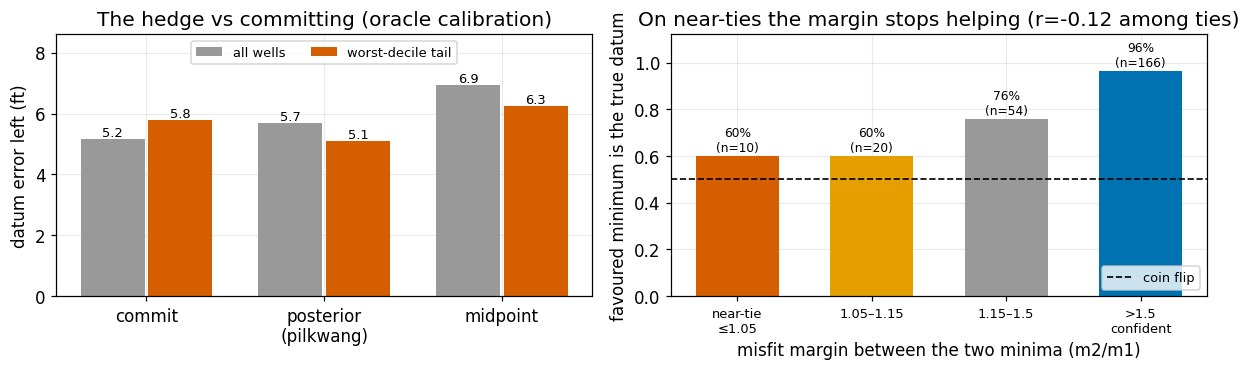

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.5))
labs = ["commit", "posterior\n(pilkwang)", "midpoint"]
allv = [datum[m][0] for m in ["commit", "posterior", "midpoint"]]
tlv  = [datum[m][1] for m in ["commit", "posterior", "midpoint"]]
x = np.arange(3)
ax[0].bar(x-0.19, allv, 0.36, color=C["grey"], label="all wells")
ax[0].bar(x+0.19, tlv,  0.36, color=C["red"],  label="worst-decile tail")
for i, (a, t) in enumerate(zip(allv, tlv)):
    ax[0].text(i-0.19, a+0.08, f"{a:.1f}", ha="center", fontsize=8.5)
    ax[0].text(i+0.19, t+0.08, f"{t:.1f}", ha="center", fontsize=8.5)
ax[0].set_xticks(x); ax[0].set_xticklabels(labs); ax[0].set_ylabel("datum error left (ft)")
ax[0].set_ylim(0, 8.6)
ax[0].set_title("The hedge vs committing (oracle calibration)")
ax[0].legend(fontsize=8.5, ncol=2, loc="upper center")

# (b) does the margin between the two minima predict which is true? bin wells by m2/m1
mr, mc = np.asarray(mar_ratio), np.asarray(mar_correct, float)
edges  = [1.0, 1.05, 1.15, 1.5, np.inf]
blab   = ["near-tie\n≤1.05", "1.05–1.15", "1.15–1.5", ">1.5\nconfident"]
share, cnt = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (mr >= lo) & (mr < hi); cnt.append(int(m.sum()))
    share.append(mc[m].mean() if m.any() else np.nan)
tie = mr <= 1.15
r_tie = np.corrcoef(mr[tie], mc[tie])[0, 1] if tie.sum() > 2 else np.nan
ax[1].bar(range(4), share, 0.62, color=[C["red"], C["orange"], C["grey"], C["blue"]])
ax[1].axhline(0.5, ls="--", lw=1.1, color="k", label="coin flip")
for i, (s, c2) in enumerate(zip(share, cnt)):
    ax[1].text(i, s+0.02, f"{s:.0%}\n(n={c2})", ha="center", fontsize=8)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(blab, fontsize=8.5)
ax[1].set_ylim(0, 1.12); ax[1].set_ylabel("favoured minimum is the true datum")
ax[1].set_xlabel("misfit margin between the two minima (m2/m1)")
ax[1].set_title(f"On near-ties the margin stops helping (r={r_tie:+.2f} among ties)")
ax[1].legend(fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()

*The hedge helps, but only directionally.* &nbsp; The result is honest but modest. On the worst-decile tail the posterior mean leaves the least datum error of the three, beating both committing and the fixed midpoint — so the hedge helps where it should — but the tail margin is only ~0.7&nbsp;ft, so call it directional (over *all* wells committing edges it, 5.2 vs 5.7&nbsp;ft, because the temperature, set wide enough to stop `p` being overconfident on the hard wells, over-hedges the easy ones where the global minimum is already right). 

*A caveat.* &nbsp; The caveat that matters most: the softmax `p` is a confidence weight, not a mode-fixer — it always backs the lower-misfit minimum, and when that is the decoy (12% of wells even under the oracle calibration) it backs the decoy too. The gain is from not fully committing, not from `p` picking the right mode. 

*The margin, read the same way.* &nbsp; The right panel shows the same degeneracy read off the margin itself: once the two minima sit within ~15% of each other, the favoured one is right at roughly coin-flip rate (small train-side n, printed on the bars) — my shift-scan view of the tie-break souldrive measured at r&nbsp;=&nbsp;+0.054 across all 773 wells. And all of this is the *oracle*-calibration ceiling; whether you can read `p` *legally* is the next question — §5c.

**Is the calibration the wall, or is there a legal route?** §4's *legal* fit was a flat-surface guess, deliberately weak. The honest legal move is to fit the GR gain and offset on the **known heel**, where `TVT` is given, then carry that calibration to the tail; nothing there uses the answer. The cell localizes the datum under four calibrations: the two from §4, the legal heel-fit, and the heel-fit after a GR-rotation denoise (a rolling median here, standing in for the FFT-rotation notch the Problem Breakdown thread proposed).

In [16]:
def _calib(src, tgt):
    v = np.isfinite(src) & np.isfinite(tgt)
    if v.sum() < 20: return None
    c, *_ = np.linalg.lstsq(np.vstack([src[v], np.ones(v.sum())]).T, tgt[v], rcond=None); return c
def _denoise(g): return pd.Series(g).rolling(7, center=True, min_periods=1).median().to_numpy()
TW = {w["wid"]: load_tw(w) for w in W}            # cache typewells once

def datum_localize(mode, dn=False):
    # same GR prep + validity filter as §5, so the oracle and flat rows reproduce its numbers exactly
    loc = n = 0
    for w in W:
        tv, tg = TW[w["wid"]]
        if tv is None: continue
        ge = pd.Series(w["GR"][w["ei"]]).interpolate(limit_direction="both").to_numpy()
        gk = pd.Series(w["GR"][w["kn"]]).interpolate(limit_direction="both").to_numpy()
        if dn: ge, gk = _denoise(ge), _denoise(gk)
        if np.sum(np.isfinite(ge)) < 20 or len(tv) < 10 or np.std(ge) < 1e-6: continue
        true = w["true"]
        if mode == "oracle":  coef = _calib(ge, twgr(true, tv, tg))
        elif mode == "flat":  coef = _calib(ge, twgr(w["last"] + (w["hwZ"][w["li"]] - w["Z"]), tv, tg))
        else:                 coef = _calib(gk, twgr(w["tvi"][w["kn"]], tv, tg))   # heel = LEGAL
        if coef is None: continue
        cal = ge * coef[0] + coef[1]; v = np.isfinite(cal)
        if v.sum() < 20: continue
        cost = np.array([np.mean((cal[v] - twgr(true + dz, tv, tg)[v]) ** 2) for dz in GRID])
        n += 1
        if abs(GRID[int(np.argmin(cost))]) <= 2: loc += 1     # truth is at dz=0
    return loc / max(n, 1)

print("GR-misfit datum localization (global min within 2 ft of the truth), by calibration:")
print(f"  oracle (illegal)          {datum_localize('oracle'):.0%}")
print(f"  flat-surface (§4 legal)   {datum_localize('flat'):.0%}")
print(f"  heel-fit (legal)          {datum_localize('heel'):.0%}")
print(f"  heel-fit + GR denoise     {datum_localize('heel', True):.0%}")

GR-misfit datum localization (global min within 2 ft of the truth), by calibration:
  oracle (illegal)          82%
  flat-surface (§4 legal)   8%
  heel-fit (legal)          80%
  heel-fit + GR denoise     84%


<a id="5c"></a>
### 5c. The legal route: heel-calibration

The flat fit localizes the datum on only ~8% of wells, but the legal heel-fit recovers ~80%, essentially the oracle's 82%, with the scan still centred on the true shape (a train-only diagnostic). The gap was the *calibration*, not a property of the data, and a GR-rotation denoise nudges it to 84% (a 7-point rolling median, a crude proxy for the proper FFT-rotation notch). So pilkwang's recipe has a legal route after all: heel-calibrate (the piece I add), then read the two minima and hedge (pilkwang's). I owe a correction to my §5 caveat, which leaned on the weak flat fit. The datum is legally pinnable to nearly the oracle's rate with an explicit fit; the calibration is no longer the bottleneck, and you do not need a separate matcher for it. The residual wrong-mode rate, about one well in eight, is unchanged by calibration, because that part is the geology, not the fit. What the legal route still cannot pin is the *shape*, the per-well dip the heel line cannot extrapolate to the tail (§6). The open legal problem moved from the datum to the slope.

*Independently measured, from the other side.* &nbsp; souldrive measured the same degeneracy from the cost-landscape side on all 773 wells: among the ~49% of wells with a clear second minimum in the bundle gap, the cost-favoured one is the correct datum just 48.8% of the time, and the margin between the two carries essentially no information about which is right (r&nbsp;=&nbsp;+0.054, p&nbsp;=&nbsp;0.30). His NCC cost surface and the GR likelihood here agree: the tie is detectable, the tie-break absent. His [Decoding Eagle Ford](https://www.kaggle.com/code/souldrive/decoding-eagle-ford-why-some-wells-are-hard) notebook has the geology and the full decomposition.

*What this replaces.* &nbsp; Stack §3 through §5 together and the single "wall" dissolves into a distribution: a good chunk of wells near-solved from clean offset plus dip, a heavy tail that is geology — the bimodal datum and the faults — not a modeling failure. That recoverable-versus-irreducible split is the honest replacement for the ~10&nbsp;ft wall I claimed before.

*Measured versus borrowed.* &nbsp; A note on what is measured versus borrowed, so I don't over-correct one mistake into a new overclaim. The Milankovitch mechanism is souldrive's geology. The SSE concentration and the likelihood degeneracy are my train-side measurements, computed on the smooth-oracle residuals in the cells above; they need the truth, so they live on train, not on the hidden test. The midpoint-versus-mode arithmetic is decision theory on an idealized well. I am not claiming to have measured the bimodal *cause* on every tail well. The ±15&nbsp;ft schematic panel in the two-panel figure above is a labeled illustration of the mechanism, not a measurement.

**The Working Notes converged here (July&nbsp;6).** Five independent writeups later reached this same floor from methods I did not have — acquisition physics (the discriminating GR band is below the instrument's floor on the scored rows), observability theory, an identifiability lemma, a selector that fails even when handed the true label, and one honest partial dissent: the posterior-mean hedge is base-dependent, not universal. The datum is not unrecovered, it is unobservable. Each note is credited, with its mechanism, in [§13](#13).

<a id="5d"></a>
### 5d. How big is the human noise floor? Someone measured it

Everything above bounds the datum from the *data* side. There is a second way to bound it, and it is the same move one level down: measure the **people**.

The target here is `manualTVT` — one geologist's reading of ambiguous logs. So the honest question behind every score on this board is how tightly a manual interpretation can be pinned down at all. You cannot answer that from the competition data, because each well carries exactly one interpretation; there is nothing to disagree with.

*The experiment that does answer it.* &nbsp; At the Geosteering World Cup 2021 — run by ROGII, the same organisers — 176 specialists steered virtual wells in real time, redrawing where they thought the layers lay as new logs arrived. Every intermediate state was recorded, **and the true geology is known**. NORCE and the University of Stavanger published it under CC BY 4.0. I lifted it out of nested JSON and reshaped it into five tidy tables, attached here as [Expert Label Noise: 176 Annotators, Known Truth](https://www.kaggle.com/datasets/georgymamarin/geosteering-world-cup-2021-expert-interpretations). The cell below runs on it directly.

In [17]:
# ---- §5d: how far apart do trained specialists land on ONE known subsurface? ----
def find_gwc():
    for c in ["/kaggle/input/geosteering-world-cup-2021-expert-interpretations", "gwc-dataset/dataset"]:
        if os.path.isfile(f"{c}/interpretations_final_gridded.csv"): return c
    g = glob.glob("/kaggle/input/**/interpretations_final_gridded.csv", recursive=True)
    return os.path.dirname(g[0]) if g else None

GWC, M2FT = find_gwc(), 3.28084
g = pd.read_csv(f"{GWC}/interpretations_final_gridded.csv")
g = g[(g["round"] == 1) & (g.scenario == "cd117866")]          # the largest round-1 cohort, one geology
piv = g.pivot_table(index="md_m", columns="player", values="tvd_shift_m").dropna(axis=1)
tru = g.groupby("md_m").truth_tvd_shift_m.first().reindex(piv.index).values * M2FT
err = lambda v: float(np.sqrt(np.mean((np.asarray(v) * M2FT - tru) ** 2)))

per   = np.array([err(piv[c]) for c in piv.columns])           # each specialist vs truth
crowd = err(piv.median(axis=1))                                # their pointwise median
print(f"specialists on this one subsurface : {piv.shape[1]}")
print(f"median specialist vs truth         : {np.median(per):5.1f} ft   (best {per.min():.1f}, worst {per.max():.0f})")
print(f"their pointwise median vs truth    : {crowd:5.1f} ft   -> {np.median(per)/crowd:.2f}x better than the median one")
print(f"specialists who beat the crowd     : {(per < crowd).sum()} of {len(per)}")

specialists on this one subsurface : 107
median specialist vs truth         :  20.5 ft   (best 3.8, worst 579)
their pointwise median vs truth    :   9.5 ft   -> 2.15x better than the median one
specialists who beat the crowd     : 10 of 107


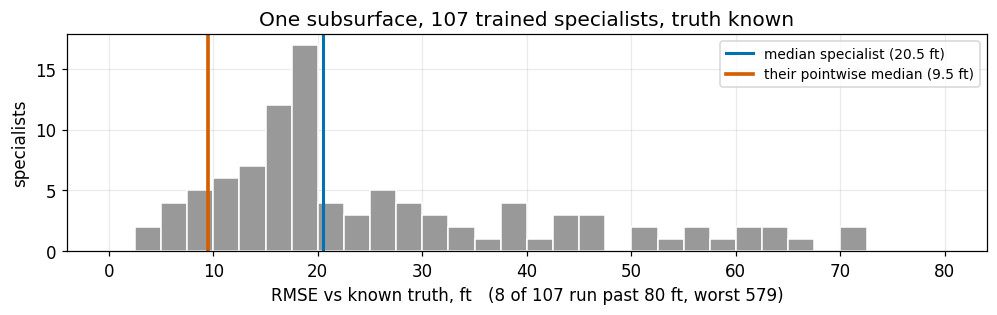

In [18]:
fig, ax = plt.subplots(figsize=(9.2, 3.0))
ax.hist(per, bins=np.linspace(0, 80, 33), color=C["grey"], edgecolor="white")
ax.axvline(np.median(per), color=C["blue"], lw=2, label=f"median specialist ({np.median(per):.1f} ft)")
ax.axvline(crowd, color=C["red"], lw=2.4, label=f"their pointwise median ({crowd:.1f} ft)")
ax.set_xlabel(f"RMSE vs known truth, ft   ({(per>80).sum()} of {len(per)} run past 80 ft, worst {per.max():.0f})")
ax.set_ylabel("specialists")
ax.set_title(f"One subsurface, {piv.shape[1]} trained specialists, truth known")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

*What it says.* &nbsp; Trained professionals reading the same rock, with the answer known, land tens of feet apart. Their pointwise median is more than twice as good as the median individual, and only a handful of them beat it — the same aggregation result §5 reached from the cost surface, arrived at from the human side instead.

*What it does not say.* &nbsp; Do not read these feet as a label-noise figure for this competition. Different task, different geology, and the Cup was timed at roughly two minutes per decision, so unhurried work would come out tighter — treat it as an **upper bound** on interpretation noise, and read the ratios rather than the feet. The dataset page carries the traps (group by scenario before comparing anything; faults in `truth.csv` hide as near-duplicate depths) and a longer walkthrough lives in [what is the precision of a manual interpretation](https://www.kaggle.com/code/georgymamarin/what-is-the-precision-of-a-manual-interpretation).

*Why it belongs here.* &nbsp; It is the same move as §9. If the label is a person's drawing, then the ruler you measure your model with has a person's spread baked into it — and that spread is measurable, on public data, by anyone who forks this.

<a id="6"></a>
## 6. The leave-field-out result, in proportion

This is the experiment that led me to the wrong "wall" claim, so let me run it honestly and then scope it correctly.

*The setup.* &nbsp; The setup is conservative by design — it is the **wall test** from §9, pointed at my own features. Cluster the wells by location (KMeans on heel X/Y), then GroupKFold so each fold leaves whole fields out, and try to predict the per-well drift slope from cheap legal features. The result: field-grouped OOF R² below zero — worse than guessing the global mean — and the shuffled-label control sits in the same place, so the harness itself is not leaking.

*Why the slope cannot transfer.* &nbsp; There is a clean way to see why the slope will not transfer. The TVT *level* is strongly coherent in space — a well's last-known TVT predicts its nearest neighbour's at correlation 0.976 — but that coherence is already yours for free, pinned by the heel. The quantity you actually have to predict, the in-zone *drift*, has nearest-neighbour correlation −0.08, essentially zero (both 265-well recomputes, not cells here; Malyshev Danil published the same correlation first, [§10](#10)). The spatial structure that exists is the part the anchor already hands you; the part you need is structureless from one well to the next.

*A mechanism, from the comments.* &nbsp; wharekawa, who reproduced the §2 ladder, put a mechanism on this failure in the comments: reconstruction error scales like the surface gradient times the distance to the wells you borrow from. My recompute agrees (separate, not a cell here). Between same-field nearest neighbours — median spacing ~490&nbsp;ft, p90 ~1.8&nbsp;kft — the surface level already differs by ~13&nbsp;ft at the median and ~79&nbsp;ft at the p90, an implied gradient of ~0.023&nbsp;ft/ft (p90 ~0.075). Both gradients are medians over neighbour *pairs*, so they are deliberately not the ratios of the medians just quoted. That is a survey-density floor, not a modeling failure: the bounded IDW below (~23&nbsp;ft) sits right on it, and the 13–129&nbsp;ft band my leaky v1 produced is the same law read at wider effective spacing. The plane fit's blow-ups are the one thing the law does not cover — that part is ill-conditioning, not geology.

*Reconstruction fails the same way.* &nbsp; Cross-well surface reconstruction fails the same way. A bounded inverse-distance average of the neighbours' surface reconstructs to about 23&nbsp;ft RMSE — still worse than the ~14.5 of carrying the last value flat on those wells. Fitting a local dipping *plane* instead does not merely fail, it diverges numerically: the trajectory is nearly one-dimensional, so the neighbours are almost collinear, the dip terms are ill-conditioned, and the extrapolation flies off (a leak-fixed re-run lands at 477&nbsp;ft within a field and 3254&nbsp;ft across fields — a blow-up of the ill-conditioned plane fit, not a geological number). An earlier version reported a gentler 13–129&nbsp;ft; that was a same-field-leak artefact, its "leave-field-out" neighbours nearly all from the same field. Either way the cross-field reconstruction does not beat flat. (These are separate train-side re-runs, not cells in this notebook.)

In [19]:
# per-well legal features (known at prediction time) + the target slope
rows = []
for w in W:
    li, kn = w["li"], w["kn"]; Zf, MDf, X, Y = w["hwZ"], w["hwMD"], w["X"], w["Y"]
    ancc_kn = w["tvi"][kn] + Zf[kn]; latd_kn = np.hypot(X[kn]-X[li], Y[kn]-Y[li])
    pre_dip = np.polyfit(latd_kn, ancc_kn, 1)[0] if latd_kn.max() > 50 else 0.0
    g = lambda a: np.gradient(a, MDf)[li]
    rows.append(dict(wid=w["wid"], x=X[li], y=Y[li],
                     slope=np.polyfit(w["s"], w["true"]-w["last"], 1)[0],
                     pre_dip=pre_dip, dz_heel=g(Zf),
                     incl=np.degrees(np.arctan2(np.hypot(g(X), g(Y)), abs(g(Zf))+1e-9)),
                     gr_pre=np.nanmean(w["GR"][kn][-50:]),
                     latspan=np.hypot(X[w["ei"][-1]]-X[li], Y[w["ei"][-1]]-Y[li])))
D = pd.DataFrame(rows)
N_FIELDS = 17                                          # match the cited block-CV (KMeans-17 on heel X/Y)
XY = D[["x","y"]].values; XYs = (XY-XY.mean(0))/(XY.std(0)+1e-9)
field = KMeans(N_FIELDS, n_init=10, random_state=SEED).fit(XYs).labels_   # spatial field clusters
feats = ["pre_dip","dz_heel","incl","gr_pre","latspan","x","y"]
y = D["slope"].values
r2 = lambda yt,yp: 1 - np.sum((yt-yp)**2)/np.sum((yt-yt.mean())**2)
oof, oof_shuf = np.zeros(len(D)), np.zeros(len(D)); yshuf = rng.permutation(y)
for k in range(N_FIELDS):
    tr, te = field!=k, field==k
    if te.sum()==0 or tr.sum()<15: oof[te]=oof_shuf[te]=y[tr].mean() if tr.sum() else y.mean(); continue
    mk = lambda yy: HGB(max_iter=250,max_depth=3,learning_rate=.05,l2_regularization=2.,random_state=SEED).fit(D.loc[tr,feats],yy[tr]).predict(D.loc[te,feats])
    oof[te], oof_shuf[te] = mk(y), mk(yshuf)
print(f"drift-slope field-OOF R² = {r2(y,oof):+.3f}")
print(f"shuffle-control     R² = {r2(y,oof_shuf):+.3f}   (≤ 0, same as the real fit ⇒ no spurious skill in the harness)")

drift-slope field-OOF R² = -0.340
shuffle-control     R² = -0.258   (≤ 0, same as the real fit ⇒ no spurious skill in the harness)


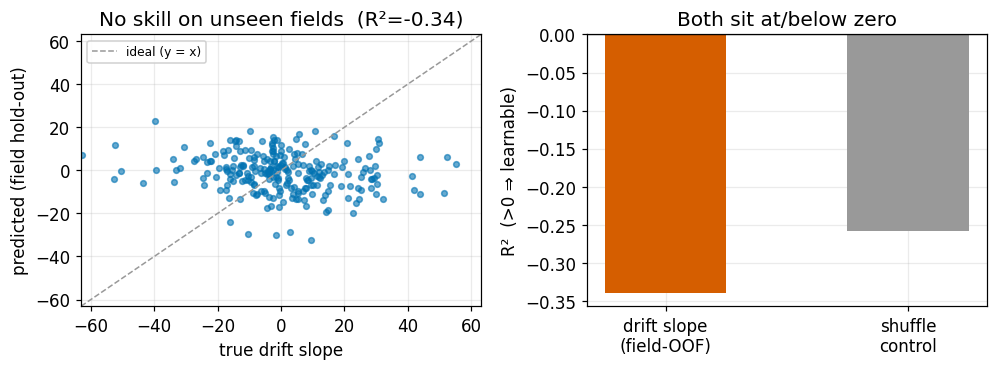

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.5))
ax[0].scatter(y, oof, s=14, alpha=.6, color=C["blue"])
lim = np.percentile(np.abs(y), 98)
ax[0].plot([-lim,lim],[-lim,lim], color=C["grey"], ls="--", lw=1, label="ideal (y = x)")
ax[0].set_xlim(-lim,lim); ax[0].set_ylim(-lim,lim)
ax[0].set_xlabel("true drift slope"); ax[0].set_ylabel("predicted (field hold-out)")
ax[0].legend(loc="upper left", fontsize=8, framealpha=.9)
ax[0].set_title(f"No skill on unseen fields  (R²={r2(y,oof):+.2f})")
labels = ["drift slope\n(field-OOF)", "shuffle\ncontrol"]
ax[1].bar(labels, [r2(y,oof), r2(y,oof_shuf)], color=[C["red"], C["grey"]], width=.5)
ax[1].axhline(0, color="k", lw=.8); ax[1].set_ylabel("R²  (>0 ⇒ learnable)")
ax[1].set_title("Both sit at/below zero")
plt.tight_layout(); plt.show()

*What I built, and why I stopped.* &nbsp; CNN, GRU and GBM all failed to beat the selector, and I mean I built them, not hand-waved: a seq2seq with multi-head cross-attention over the well's 401-token typewell memory bank, a dilated 1-D CNN with a ~1000-sample receptive field, a bidirectional GRU, and a LightGBM on band-limited typewell-inversion features. None cleared the per-well selector — though the seq2seq never fully converged, so I won't claim that door is 100% shut. What made me stop was an external, checkable benchmark: hengck23, a Grandmaster, was at 7.583 after 26 submissions on a self-trained CNN/MTP/SDF stack, worse than the best free public fork of the time at 7.519 (both early-July figures; the cluster has since moved to ~6.3&ndash;6.5). If a Grandmaster's heavy-ML lands behind the fork wave, my self-trained heavy-ML had negative expected edge for a bronze target, so I put the compute back into alignment quality. The board's own discussion has since converged on the same split: Tucker says the sub-6 CVs come from non-tabular models, and k256 reported his best non-tabular single method at 7.098 against a tabular best of 6.798 (early July) — the frontier is the matching, not the model class.

*What is real.* &nbsp; The finding is real: the per-well drift slope is not learnable from the cheap legal features I tried when you generalize to unseen fields. I stand by that.

*What I got wrong.* &nbsp; What I got wrong was the scope. This is leave-*whole-field*-out, deliberately the hardest split I could pose. The competition does not ask you to extrapolate to brand-new fields, and I should not assume more about the test geometry than the host has confirmed. My selector's honest level was ~10 pooled (~10.9 under this block-CV) — its ceiling under one hard split, not the task's floor. Tucker's ~5 pooled per-row, as I read it, goes well below that without ever touching the cross-field slope transfer I proved hard.

*The boundary, stated cleanly.* &nbsp; So state the boundary cleanly, because both facts are true and answer different questions. The negative result says cross-field slope transfer is hard from cheap features; that is real. It does not say the per-well dip is unreadable — the board heads and my own smooth oracle at ~3.0 say the opposite — and it is not a within-field learnability claim either way.

*What survives.* &nbsp; The useful caution survives intact: a within-sample slope fit looks predictive and evaporates on hold-out, so "I found a feature that predicts the drift" usually means "I leaked." Still true. It just was not the floor of the task.

<a id="6b"></a>
### 6b. Two community claims, run through the ruler

Two concrete mechanisms are circulating in the forum as of late July, both surfaced in one
question thread: *split your wells by drilling azimuth — they traverse the layers
in reverse order* (De DQ, in [stevenleehans's thread](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/726465)), and *the top-team signal is copying the nearest
neighbour's TVT profile wholesale* (same thread, with stevenleehans's own numbers). Both are exactly
the kind of claim §9 exists for, so here is each one under the harness — mechanism first, transfer
second, shuffle control on both.

In [21]:
# ---- claim 1: drilling azimuth. Mechanism test: is the apparent dip one regional vector? ----
az_rows = []
for w in W:
    kn, ei = w["kn"], w["ei"]
    Xf, Yf, Zf = w["X"], w["Y"], w["hwZ"]
    # signed ANCC slope along the whole lateral (known part uses TVT_input, eval part the truth)
    ancc = np.full(len(Xf), np.nan)
    ancc[kn] = w["tvi"][kn] + Zf[kn]
    ancc[ei] = w["true"] + Zf[ei]
    m = np.isfinite(ancc)
    if m.sum() < 400: continue
    sxy = np.hypot(np.diff(Xf[m]), np.diff(Yf[m])).cumsum(); sxy = np.insert(sxy, 0, 0)
    if sxy[-1] < 1000: continue
    az_rows.append(dict(az=np.arctan2(Yf[m][-1]-Yf[m][0], Xf[m][-1]-Xf[m][0]),
                        slope=np.polyfit(sxy, ancc[m], 1)[0]))
AZ = pd.DataFrame(az_rows)
Xm = np.column_stack([np.cos(AZ.az), np.sin(AZ.az)])
coef, *_ = np.linalg.lstsq(Xm, AZ.slope, rcond=None)
r2_az = 1 - np.sum((AZ.slope - Xm@coef)**2) / np.sum((AZ.slope - AZ.slope.mean())**2)
ctrl = []
for _ in range(200):
    Xs = Xm[rng.permutation(len(AZ))]
    c2, *_ = np.linalg.lstsq(Xs, AZ.slope, rcond=None)
    ctrl.append(1 - np.sum((AZ.slope - Xs@c2)**2) / np.sum((AZ.slope - AZ.slope.mean())**2))
print(f"wells: {len(AZ)}")
print(f"slope ~ cos/sin(azimuth):  R² = {r2_az:.3f}   (shuffle control: median {np.median(ctrl):+.3f})")
print(f"regional dip vector: azimuth {np.degrees(np.arctan2(coef[1], coef[0]))%360:.0f} deg, "
      f"{np.hypot(*coef)*100:.2f} ft per 100 ft of lateral")

wells: 250
slope ~ cos/sin(azimuth):  R² = 0.921   (shuffle control: median -0.023)
regional dip vector: azimuth 112 deg, 3.44 ft per 100 ft of lateral


In [22]:
# ---- claim 1, transfer test: does azimuth predict the DRIFT slope beyond the heel's own dip? ----
# reuses §6's D / field / oof machinery verbatim; only the feature list changes
_az_eval = [np.arctan2(w["Y"][w["ei"]][-1]-w["Y"][w["ei"]][0],
                       w["X"][w["ei"]][-1]-w["X"][w["ei"]][0]) for w in W]
D["cos_az"], D["sin_az"] = np.cos(_az_eval), np.sin(_az_eval)
for label, ft in [("pre_dip only          ", ["pre_dip"]),
                  ("pre_dip + azimuth     ", ["pre_dip", "cos_az", "sin_az"]),
                  ("azimuth only          ", ["cos_az", "sin_az"])]:
    o, osh = np.zeros(len(D)), np.zeros(len(D)); ysh = rng.permutation(y)
    for k in range(N_FIELDS):
        tr, te = field != k, field == k
        if te.sum() == 0 or tr.sum() < 15:
            o[te] = osh[te] = y[tr].mean() if tr.sum() else y.mean(); continue
        f_ = lambda yy: HGB(max_iter=250, max_depth=3, learning_rate=.05,
                            l2_regularization=2., random_state=SEED
                            ).fit(D.loc[tr, ft], yy[tr]).predict(D.loc[te, ft])
        o[te], osh[te] = f_(y), f_(ysh)
    print(f"{label} field-OOF R² = {r2(y, o):+.3f}   shuffle {r2(ysh, osh):+.3f}")

pre_dip only           field-OOF R² = -0.093   shuffle -0.076
pre_dip + azimuth      field-OOF R² = -0.231   shuffle -0.124
azimuth only           field-OOF R² = -0.165   shuffle -0.094


*Verdict on the azimuth split.* &nbsp; The mechanism is real and strikingly clean: the wells fly in
two anti-parallel swarms, and one regional dip vector explains R² = 0.92 of the signed apparent dip
across every well in the sample — drill up-dip and the label climbs, drill down-dip and it falls. But
the transferable content is already priced in: under the same field-grouped protocol as §6, all three
feature sets land at or below zero, just like their shuffle controls — adding azimuth to the heel's own
measured dip buys no out-of-field skill, it only adds variance. The regional vector is fully visible in each well's
known section, so azimuth is a coarse proxy for a feature you already have. One honest nuance: for
sequence models that never extract the heel dip explicitly, splitting by direction may still help as
*conditioning* — it just adds no information a tabular model with `pre_dip` lacks.

In [23]:
# ---- claim 2: the neighbour ladder, over ALL wells. Borrow the nearest foreign ANCC, datum from own heel ----
pts, vals, keep = [], [], []
for f in sorted(glob.glob(f"{TRAIN}/*__horizontal_well.csv")):
    dfn = pd.read_csv(f, usecols=["X", "Y", "Z", "ANCC", "TVT", "TVT_input"])
    a = dfn.dropna(subset=["ANCC"])
    if len(a) < 50: continue
    step = max(1, len(a)//600)                          # ~10 ft spacing for the tree
    pts.append(a[["X", "Y"]].values[::step]); vals.append(a["ANCC"].values[::step])
    tvi_, tv_ = dfn["TVT_input"].to_numpy(float), dfn["TVT"].to_numpy(float)
    kn_ = np.flatnonzero(~np.isnan(tvi_)); ei_ = np.flatnonzero(np.isnan(tvi_) & np.isfinite(tv_))
    if len(kn_) < 300 or len(ei_) < 300: keep.append(None); continue
    keep.append(dict(X=dfn.X.values, Y=dfn.Y.values, Z=dfn.Z.values,
                     tvi=tvi_, tv=tv_, kn=kn_[::5], ei=ei_[::5], last=tvi_[kn_[-1]]))
owner = np.concatenate([[i]*len(p) for i, p in enumerate(pts)]).astype(np.int64)
P_all, A_all = np.vstack(pts), np.concatenate(vals)
tree = cKDTree(P_all)
lad, skipped = [], 0
for i, w in enumerate(keep):
    if w is None: continue
    rows_ = np.concatenate([w["kn"], w["ei"]])
    q = np.column_stack([w["X"][rows_], w["Y"][rows_]])
    dd, jj = tree.query(q, k=192)
    foreign = owner[jj] != i
    first = foreign.argmax(axis=1); ok = foreign[np.arange(len(q)), first]
    if not ok.all(): skipped += 1; continue
    dist = dd[np.arange(len(q)), first]; a_n = A_all[jj[np.arange(len(q)), first]]
    nk = len(w["kn"])
    b = np.median(w["tvi"][w["kn"]] - (a_n[:nk] - w["Z"][w["kn"]]))
    pred = a_n[nk:] - w["Z"][w["ei"]] + b
    truth = w["tv"][w["ei"]]
    lad.append(dict(nd=float(np.median(dist[nk:])),
                    nbr=float(np.sqrt(np.mean((pred - truth)**2))),
                    carry=float(np.sqrt(np.mean((w["last"] - truth)**2)))))
L = pd.DataFrame(lad)
L["bin"] = pd.cut(L.nd, [0, 150, 300, 600, 1200, 1e9],
                  labels=["<150", "150-300", "300-600", "600-1200", ">1200"])
G = L.groupby("bin", observed=True).agg(n=("nd", "count"), nbr=("nbr", "median"), carry=("carry", "median"))
print(f"wells measured: {len(L)} of the full train set")
display(G.round(2).style.set_table_styles([{"selector": "th", "props": [("font-size", "13px")]}])
        .set_properties(**{"font-size": "13px"}))
print(f"\nmedian distance to the nearest foreign lateral: {L.nd.median():.0f} ft (p90 {L.nd.quantile(.9):.0f})")
print(f"skipped {skipped} wells whose nearest foreign lateral lies beyond the search horizon — "
      f"the most isolated wells, i.e. exactly the regime where borrowing has nothing to borrow")

wells measured: 628 of the full train set


,n,nbr,carry
bin,,,
<150,41,6.070000,10.200000
150-300,135,9.940000,10.040000
300-600,384,10.170000,10.400000
600-1200,68,18.240000,10.960000



median distance to the nearest foreign lateral: 349 ft (p90 607)
skipped 138 wells whose nearest foreign lateral lies beyond the search horizon — the most isolated wells, i.e. exactly the regime where borrowing has nothing to borrow


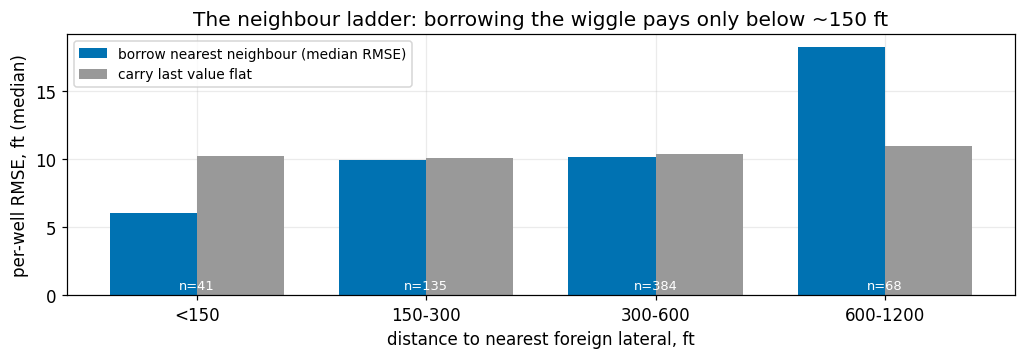

In [24]:
fig, ax = plt.subplots(figsize=(9.6, 3.4))
xb = np.arange(len(G)); wd = 0.38
ax.bar(xb - wd/2, G.nbr,   wd, color=C["blue"], label="borrow nearest neighbour (median RMSE)")
ax.bar(xb + wd/2, G.carry, wd, color=C["grey"], label="carry last value flat")
for i, n in enumerate(G.n): ax.text(i, 0.4, f"n={n}", ha="center", fontsize=8.5, color="white")
ax.set_xticks(xb); ax.set_xticklabels(G.index); ax.set_xlabel("distance to nearest foreign lateral, ft")
ax.set_ylabel("per-well RMSE, ft (median)")
ax.set_title("The neighbour ladder: borrowing the wiggle pays only below ~150 ft")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

*Verdict on the neighbour ladder.* &nbsp; The community number reproduces at the close end: with a
foreign lateral inside 150 ft, wholesale borrowing lands a median 6.1 ft against 10.2 for carrying the
last value flat — per-well line-oracle territory, exactly the regime stevenleehans reported. But that
is 41 wells of the 628 measured. From 150 to 600 ft the borrow is a coin-flip against carry-flat, with
a heavy tail of datum blow-ups, past 600 ft it is actively destructive (18.2 vs 11.0), and the hundred-plus
most isolated wells do not even have a foreign lateral inside the search horizon. This is the *naive* recipe —
nearest point, median datum — so read it as a lower bound on what marker-frame alignment can extract;
what it bounds honestly is the claim that neighbours are free signal. They are free for roughly one
well in twenty, once you count the isolated wells the search never reaches.

*The two measurements close a loop from §6.* &nbsp; The regional dip above is 3.4 ft per 100 ft; the
median distance to a foreign lateral is ~350 ft. Multiply and you get ~12 ft — the same scale as the
carry-flat floor the ladder measures (10–11 ft in the middle bins). wharekawa's survey-density law
(error ≈ gradient × spacing), measured here from two independent directions, meets its own prediction
in the middle.

<a id="7"></a>
## 7. Traps that look like progress

A few things on this task feel like progress without being it. Most are about how results are read; the last one I walked into myself.

**A move smaller than your own noise floor.** This is the first trap because it is the one that costs the most and shows the least. Resubmitting an unchanged notebook of mine moves the score by about 0.037&nbsp;ft, so any single A/B on that pipeline needs roughly 0.10&nbsp;ft before it means anything. Half the comparisons I had been drawing conclusions from sit under that bar, including the one that told me where the best likelihood width was. The opening has the table. Your own floor is a different number, and you only get it by resubmitting something unchanged four or five times.

**The CV→LB mirage.** A deep model can post a low validation RMSE on train folds and land far worse when it runs for real. At least one public notebook here advertises a single-digit fold RMSE yet scores around 14 when actually run. A low cross-validation number is a claim about *seen* wells; the leaderboard is a claim about *unseen* ones, and on this task they come apart hard. Validate on a hold-out shaped like the real test, not the friendliest fold.

**Seed and refork variance.** The strong public pipeline contains a stochastic particle filter. Re-running the same code, or forking a notebook whose public score is a few thousandths better, draws a fresh sample, and the run-to-run spread is comparable to the fork-to-fork gaps people chase (the real cluster now lives around 6.3 to 6.5). pilkwang put a clean number on this in the comments: his byte-identical notebooks scored 7.201 to 7.286 on the public board, and a wider set identical up to comment encoding reaches down to 7.168. The whole spread is the particle filter reseeding, with nothing changed in the code. So "a fork that reads 0.03 better than its neighbour" is just the lucky tail of that spread, and picking your final submission by best public score is selecting on it. My own two lineages land in the same place. The picture below puts all three spreads on one axis, centred on their own means because they were taken at different points on the board and only their width is comparable. The gap people refork for fits several times over inside every one of them.

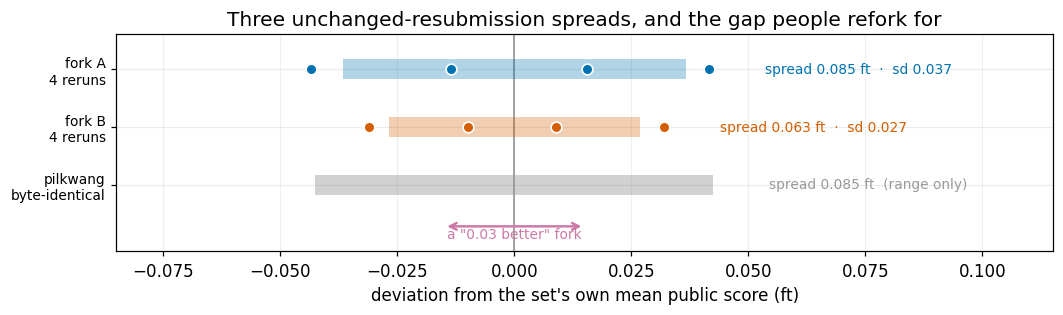

In [25]:
# ---- Section 7: every published reseed spread on one axis, centred on its own mean ----
# Three independent measurements of what an UNCHANGED submission does, plus the size of the
# fork-to-fork gaps people chase. Centred, because the three were taken at different points
# on the board and only their WIDTH is comparable.
import numpy as np, matplotlib.pyplot as plt

A = np.array([6.700, 6.726, 6.641, 6.671])          # fork A (ayodeji v599), 4 reruns
B = np.array([7.219, 7.240, 7.259, 7.282])          # fork B (baidalinadilzhan), 4 reruns
PILK = (7.201, 7.286)                                # pilkwang, byte-identical, range only

fig, ax = plt.subplots(figsize=(9.8, 3.0))
rows = [
    ("pilkwang\nbyte-identical", (PILK[0] - np.mean(PILK), PILK[1] - np.mean(PILK)), None, C["grey"]),
    ("fork B\n4 reruns", None, B - B.mean(), C["red"]),
    ("fork A\n4 reruns", None, A - A.mean(), C["blue"]),
]
for yi, (lab, rng_, pts, col) in enumerate(rows):
    if pts is not None:
        sd = pts.std(ddof=1)
        ax.barh(yi, 2 * sd, left=-sd, height=.34, color=col, alpha=.30, zorder=2)
        ax.plot(pts, np.full(len(pts), yi), "o", color=col, ms=7, zorder=4,
                markeredgecolor="white", markeredgewidth=1.1)
        ax.text(pts.max() + .012, yi, f"spread {pts.max()-pts.min():.3f} ft  \u00b7  sd {sd:.3f}",
                va="center", fontsize=9, color=col)
    else:
        ax.barh(yi, rng_[1] - rng_[0], left=rng_[0], height=.34, color=col, alpha=.45, zorder=2)
        ax.text(rng_[1] + .012, yi, f"spread {rng_[1]-rng_[0]:.3f} ft  (range only)",
                va="center", fontsize=9, color=col)
ax.axvline(0, color="#888", lw=1, zorder=1)

# the delta people refork for
ax.annotate("", xy=(0.015, -0.72), xytext=(-0.015, -0.72),
            arrowprops=dict(arrowstyle="<->", color=C["purple"], lw=1.6))
ax.text(0, -0.92, 'a "0.03 better" fork', ha="center", fontsize=9, color=C["purple"])

ax.set_yticks(range(len(rows))); ax.set_yticklabels([r[0] for r in rows], fontsize=9)
ax.set_xlim(-0.085, 0.115); ax.set_ylim(-1.15, len(rows) - 0.4)
ax.set_xlabel("deviation from the set's own mean public score (ft)")
ax.set_title("Three unchanged-resubmission spreads, and the gap people refork for")
ax.grid(axis="x", alpha=.18)
plt.tight_layout(); plt.show()


**The blend ceiling.** Stacking the public forks has its own ceiling. fle3n's public blend diagnoses it: the two strongest public engines carry error-correlation ρ ≈ 0.89, so the optimal blend weight sits near ½ and the blended RMSE is flat to under 0.001&nbsp;ft around it (it lands near 7.57, an early-July figure). That is his estimate from three leaderboard anchors rather than a board fact, but the point holds — two engines whose errors correlate about 0.89 leave almost nothing for a re-weighting to recover. More signal needs a *decorrelated* source, not another re-tune of the same two.

**Chasing the ambiguous tail.** This is the counterintuitive one. On a bimodal well (§5), committing to a mode — the move that feels like finally *solving* that well — raises your expected error versus the midpoint hedge (about 21 vs 15 on the idealized 50/50 well). So apparent progress on the hardest wells can run in the wrong direction. Spend the effort where the error is recoverable, and hedge the tail.

**The over-strict split** — a meta-trap, since I fell into it: a deliberately conservative validation split can over-reject. My leave-field-out told me "unlearnable," and I generalized that to "the task's floor." Match the split to the test the competition actually scores, or a pessimistic guardrail turns into a false ceiling.

<a id="8"></a>
## 8. What to do if you are stuck near the cluster

- **The leverage is the median wells, not the tail.** Clean structural smoothing of the offset plus piecewise dip, and better per-well GR alignment to the typewell — that is where the gap from the fork cluster down to the heads lives, and it is per-well, not cross-field. A sizable share of wells can reach 3–5&nbsp;ft (the §2 cell prints how many).
- **Estimate the mode weight, predict the posterior mean.** On a bimodal well the variance is irreducible, so the right estimate is `p·a + (1−p)·b`, not a commitment to one mode (§5). The detector and the hedge collapse into one object: read `p` via the two-position softmax over the relative depths of the two minima in the §4 shift scan, as in §5. §5c shows that a legal heel-calibration makes those depths trustworthy: it recovers the oracle localization, so the datum needs no separate matcher; what the legal route still cannot pin is the per-well shape (§6). The estimate then moves off the midpoint toward whichever mode `p` favours as `p` leaves ½. A particle filter kept from collapsing to one mode carries that `p` and emits the posterior mean for free — which is also why a blanket jump-guard backfires here, since suppressing the big jump deletes the second mode.
- **Spend a hold-out budget before a tuning budget.** Validate on a split shaped like the real test, and keep the harsh leave-whole-field-out as a pessimistic guardrail rather than the target. If you can construct a within-field hold-out, run it too as a second, less-pessimistic reading — but neither split is confirmed to match the hidden test geometry, so treat them as bracketing it. Run a seed sweep before trusting a small delta; an afternoon of hold-out budget beats a week of tuning.
- **Drop the confirmed dead end.** Cross-well surface reconstruction across fields fails badly — the dip-plane fit blows up on the near-collinear neighbours, and even a bounded IDW average cannot beat flat (§6). Within-well typewell matching transfers; the cross-field offset does not.
- **Bound any GR-to-typewell search, or it will lie to you confidently.** Real per-well excursions are ~15–30&nbsp;ft, so give a matcher a window of about ±60&nbsp;ft around the last known TVT and no more. Let it roam much further and the §4 self-similarity takes over: a naive anchored Viterbi given a ±140&nbsp;ft band scored 29 RMSE against 15 for carrying flat, and a slope-following particle filter blew up to 34–58 across its whole tuning sweep — every variant allowed to wander lost to doing nothing. The bounded per-well path was also the field-robust one: it beat flat on all eight held-out fields (+2.75 to +8.34&nbsp;ft), while the three obvious far-zone patches (shrinking the far zone, a distance-ramped hold, cross-scale averaging) all died on held-out fields. (Separate train-side runs, not cells here; my own public-LB optimum was an interior blend, so read the all-fields win as robustness, not a board claim.) And the look-ahead is legal (Tiago thread), so whole-trace matching is allowed — use it.

<p style="background-color:#eef6ff;padding:16px;color:#111;font-size:15px;border:2px solid #9ec5ff;border-radius:6px">
<strong>If you keep one thing:</strong> resubmit something unchanged four or five times before you believe any A/B; on my pipeline a move under about 0.10&nbsp;ft means nothing. Then: the floor is not ~10 — the board heads sit well below it, so the recoverable part runs deeper than my selector reached. Spend your effort on median-well GR alignment and dip smoothing, and on the bimodal tail estimate the mode weight and predict the posterior mean rather than committing to one mode.
</p>

<a id="9"></a>
## 9. Fork the ruler, not the model

Fork the top pipeline for a score 0.03 better than its neighbour and you have forked the particle filter's lucky seed, not an edge ([§7](#7)) — that is what forking the *model* gets you. The **ruler** is the other thing here — and it has nothing to do with my predictions. These three helpers read *your* regression, not mine.

`oracle_ceiling(wells)` takes your per-group `(true, s)` and returns the constant / line / smooth RMSE floor for *your* data — your version of the §2 ladder. It answers whether your latest gain is real structure or noise below the floor.

`tail_concentration(wells)` fits the smooth oracle per group and returns the worst-10% share of the total squared error — the number that decides whether to chase the median or the tail. Your figure will differ from §5; that one is my train sample, this reads your tail.

The **wall test** (`wall_test(D, feats)`) leaves a whole group out and checks whether your feature survives, with a shuffled-label control so you know the test itself isn't the leak. Read it two ways. A feature that looks predictive in-sample and dies under the wall test was leaking — that is the check working. A feature that survives a within-group split but dies leave-group-out is fighting extrapolation, harder than what the competition scores, so don't read it as a verdict on the floor. Pair it with a within-group or random-row split to see both the harsh and the realistic number.

None of it is ROGII. A "well" is just a group; "measured depth" is just a within-group position; and the wall test takes **any group column** — spatial fields are one case, cross-validation folds and entity ids are others (pass `group_col=`; it clusters heel coordinates only as a fallback). If a feature you love dies under the wall test, that is the tool doing its job, and better to find out now than on your private split.

I am not asking you to fork this. I am telling you what forking is for.

In [26]:
# ---- reusable harness: drop your own per-well (true, s) in and read the ceiling / tail / wall ----
def oracle_ceiling(wells):
    # wells: list of dicts with 'true' (eval truth) and 's' (normalized MD 0..1). Returns the ceiling ladder.
    E = {k: [] for k in ["constant", "line", "smooth"]}
    for w in wells:
        t, s = np.asarray(w["true"], float), np.asarray(w["s"], float)
        E["constant"].append(t - t.mean())
        E["line"].append(t - np.polyval(np.polyfit(s, t, 1), s))
        E["smooth"].append(t - robfit(s, t, 6))
    return {k: rmse(np.concatenate(v)) for k, v in E.items()}

def tail_concentration(wells, frac=0.10):
    # worst-frac share of total smooth-oracle SSE — your version of the §5 tail.
    # your share will differ from the §5 figure (that's my train sample); this reads YOUR tail.
    sse = np.array([float(np.sum((np.asarray(w["true"], float) - robfit(np.asarray(w["s"], float), np.asarray(w["true"], float), 6))**2)) for w in wells])
    o = np.argsort(sse)[::-1]; k = max(1, int(len(sse)*frac))
    return round(float(sse[o[:k]].sum()/sse.sum()), 3)

def wall_test(D, feats, target="slope", group_col=None, n_fields=17, seed=42):
    # The HARD leave-one-GROUP-out test + a leak check, NOT a verdict on the task floor.
    # D: one row per group, with feature columns + a target column, and EITHER a group_col
    #    (fold id, entity id, time block, field...) OR x,y coordinates that get clustered into
    #    n_fields pseudo-fields when group_col is None. Group-out OOF R^2 (+ shuffle control).
    # Pair with a within-group or random-row split to get the realistic (less pessimistic) number.
    if group_col is not None:
        fld = pd.factorize(D[group_col].values)[0]; n_fields = int(fld.max()) + 1
    else:
        XY = D[["x","y"]].values; XYs = (XY-XY.mean(0))/(XY.std(0)+1e-9)
        fld = KMeans(n_fields, n_init=10, random_state=seed).fit(XYs).labels_
    y = D[target].values; rg = np.random.RandomState(seed); ys = rg.permutation(y)
    oof = np.zeros(len(D)); oos = np.zeros(len(D))
    for k in range(n_fields):
        tr, te = fld!=k, fld==k
        if te.sum()==0 or tr.sum()<15: oof[te]=oos[te]=y[tr].mean() if tr.sum() else y.mean(); continue
        f = lambda yy: HGB(max_iter=250,max_depth=3,learning_rate=.05,l2_regularization=2.,random_state=seed).fit(D.loc[tr,feats],yy[tr]).predict(D.loc[te,feats])
        oof[te], oos[te] = f(y), f(ys)
    r2 = lambda a,b: 1-np.sum((a-b)**2)/np.sum((a-a.mean())**2)
    return dict(field_oof_r2=round(r2(y,oof),3), shuffle_r2=round(r2(y,oos),3))

def posterior_mean(p, pred_lo, pred_hi):
    # squared-loss-optimal estimate on a two-mode well (pilkwang): p*lo + (1-p)*hi.
    # p = P(low mode) read from the two §4 shift-scan minima via a two-position softmax;
    # midpoint is the p=0.5 special case. apply only where a second mode is actually present.
    p = np.asarray(p, float)
    return p*np.asarray(pred_lo, float) + (1.0-p)*np.asarray(pred_hi, float)

# design notes: the oracle ladder is train-only / pooled row-RMSE; the reference lines are the REAL
# public LB (see the dated figures in the opening); the field-OOF is a negative result on cheap features under a hard
# leave-field-out split; numbers shift a few hundredths across seeds/subsamples; no submission here.
print("ceiling:", {k: round(v,2) for k,v in oracle_ceiling(W).items()})
print("tail   :", tail_concentration(W), "(worst-10% share of SSE)")
print("wall   :", wall_test(D, feats))

ceiling: {'constant': 9.07, 'line': 6.59, 'smooth': 3.0}
tail   : 0.398 (worst-10% share of SSE)
wall   : {'field_oof_r2': np.float64(-0.34), 'shuffle_r2': np.float64(-0.133)}


<a id="10"></a>
## 10. What is not mine

Working on this in July I reached several results that turned out to be in print already, some with sharper numbers than mine. This section exists because I nearly published them as new.

- **pilkwang**, on the measurement this revision opens with. He reported a byte-identical reseed spread in the comments of an earlier version of this notebook, 7.201 to 7.286, before I ran mine. What the opening adds is the standard deviation and the use I put it to, not the observation.
- **Malyshev Danil**, on the per-well datum being unidentifiable: a James&ndash;Stein shrink on the heel-dip offset estimator that lands near zero, which is the estimator reporting it carries almost no exploitable signal. [LeeDongHyuk](#13) reached a shrink of zero by a different route.
- **Malyshev Danil** again, on neighbours: the nearest-neighbour drift correlation is &minus;0.08. Neighbouring wells do not tell you which way this well's datum went. My own 265-well recompute in [&sect;6](#6) agrees, and his was first.
- **souldrive**, on the structural surface: holding `TVT + Z` constant is about six times worse than holding TVT flat, because TVT encodes what the driller was steering to, while the surface swings with dip and with the wellbore's own vertical motion. The near-coin-flip tie-break rate in [&sect;5](#5) is his measurement too.
- **radiant-allomancer**, on whole-well sequence models: a stack of recurrent models over whole wells reaching 7.762 on their own cross-validation, a whole-well trellis alongside it, and a long list of architectures that did not work.

One the other way round, for symmetry: [Murat A. Genc](#13) reproduced [&sect;6](#6)'s field-grouped negative result from his own pipeline after this notebook published it. Independent reproduction is worth more to me than priority, in both directions.


<a id="11"></a>
## 11. Two corrections to earlier versions

I got two things wrong in the first version of this notebook, and I would rather state them plainly than bury them.

**Correction 1: there is no leak.** I claimed the public leaderboard was scored on three train-copy wells, so it read generously. It is not. That local `data/test/` folder is example data, replaced by the real hidden test (about 200 wells) at scoring, confirmed on the Data page and by Ioannis M and the host. The public leaderboard is about 26% of those hidden wells, scored honestly, and the private set decides medals. I retract the leak entirely. The byte-identical example wells and the ~0.007 ANCC coincidence I misread are detailed in [&sect;12](#12).

**Correction 2: ~10&nbsp;ft is not a wall.** I framed ~10&nbsp;ft as the task's floor. It is not. The ~10 was *my selector's* ceiling, a per-well GR particle filter plus beam search, under a deliberately hard split that leaves whole fields out (block-CV ~10.9). One thing on the board already proves ~10 is not the floor: the heads sit far below it. My smooth oracle ([&sect;2](#2)) at ~3.0 is a train-side ceiling, not a board fact — it says a degree-6 shape can represent the tail once you already know the answer, not that anyone can recover it. Tucker Arrants described reaching about 5 pooled per-row using per-well data only, a cross-validation figure on train rather than a leaderboard score, so [&sect;7](#7)'s transfer caveat applies to it too. Even so, at least one head is simply matching GR better than my selector did. The gap is method quality, not a leak.


<a id="12"></a>
## 12. Design choices and limitations

- **The oracle ladder is on train wells** (it needs the truth) and is *pooled* row-RMSE on a 250-well sample. The leaderboard reference lines are the real, honestly-scored public LB (carry-last 15.883, fork cluster about 6.3 to 6.5, top three 4.679/4.902/5.064, checked 2026-07-26). Bars and dashed lines are separate categories on a shared scale; the qualitative ordering carries the argument. The agreement between my ~16 flat oracle and the 15.883 baseline is a scale sanity check, not a validation — different well sets, same procedure.
- **The leave-field-out result is a negative result for the cheap features under a field-grouped split.** A fundamentally different signal could exist; the evidence says the cheap ones do not transfer across fields. It answers the harder cross-field question, not within-field learnability.
- **The bimodal-tail numbers are part measured, part borrowed.** The Milankovitch mechanism is souldrive's. The SSE concentration (worst-10% share) and the likelihood degeneracy are my own train-side measurements on the smooth-oracle residuals; the printed numbers are sample-specific and will shift on other data. The companion split — 63 of 355 wells with per-well bias over 8&nbsp;ft carrying 73% of the error — is read from my selector's own out-of-fold predictions, an aggregate computed offline (the per-well CSV is not shipped); it is a train-side measurement, not the hidden test. The 0.976 / −0.08 neighbour correlations, the dip-plane re-run and the neighbour-spacing/gradient estimator (§6), the oracle GR-registration and the aligner tournament (§4), and the bounded-window field-CV runs (§8) are likewise separate train-side recomputes, not cells here. fle3n's engine correlation (ρ≈0.89, §7) is his own published estimate from three leaderboard anchors, not mine. The midpoint-versus-mode result is decision theory on an idealized 50/50 well. None of it is measured on the hidden test.
- **The public-LB fraction is approximate.** Roughly 26% of the ~200 hidden wells, on the order of 50; the private set decides medals; the host excluded one outlier private well.
- **On the retracted leak.** The visible `data/test/` example wells are byte-identical to the first three train wells, and an ANCC-cheat scored ~0.007 against that example set. That is what copies would do, and it is what I misread as the public LB being scored on copies. The real public LB is the hidden wells.
- **Subsample and seed.** Numbers shift a few hundredths across seeds and sample sizes; the ordering and signs are stable. Re-run with `N_WELLS = 773` to confirm.
- **No submission here.** This notebook scores nothing and is not meant to.

<a id="13"></a>
## 13. References and a question for you

The corrected thesis leans on more of the community than the first version did. Each of these is worth an upvote.

**The structure of the task**
- [franticXu — formation columns are derived from the typewell, not independent 3D surfaces](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/708167): the one-degree-of-freedom result with the thickness evidence, and the point that `TVT` is cumulative vertical distance, not a single-layer thickness.
- [Tabish — Problem Breakdown](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/708367): the typewell as a GR-vs-TVT lookup, shared subsequences of a master sequence, the piecewise-linear dip ("parallel jagged lines"), and the GR-rotation denoising lever (Shrey first spotted the rotation, MY0705 proposed the FFT denoise).
- [pilkwang — EDA: target-free alignment for TVT](https://www.kaggle.com/code/pilkwang/rogii-eda-target-free-alignment-for-tvt): the `TVT = −Z + S(X,Y) + b` framing and the GR-residual scale, with a careful look at leakage and overlap. In the comments here he also turned the §5 hedge into a calibrated posterior mean and supplied the seed-variance numbers cited in §7.

**The irreducible tail**
- [souldrive — the ±15 ft datum](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/711878): the Milankovitch / bimodal-datum geology that §5 is built on. souldrive also publicly endorsed the first version of this notebook; the §5 synthesis is partly his.

**The writeup wave — independent confirmations (July 2026).** The Working Note wave converged on the recoverable/irreducible split from angles this notebook did not have.
- [Anthony Yanza — The Acquisition Physics of the ROGII Tail](https://www.kaggle.com/writeups/anthonyyanza/the-acquisition-physics-of-the-rogii-tail-a-measu): measures the wireline-to-LWD tool response and coherence spectrum, showing the fine Milankovitch band (5–32&nbsp;ft) sits at coherence 0.03–0.11 on the scored toe rows — below the instrument's floor, the acquisition-physics reason the datum is irreducible.
- [LeeDongHyuk — Anatomy of an Unobservable Datum](https://www.kaggle.com/writeups/odyssey189/anatomy-of-an-unobservable-datum): seven information gates at ≈0, a James–Stein shrink of zero, and navigation-observability theory, all landing on the same unobservable offset.
- [Myckel Uribe — The Predictability Boundary of Pre-Drill Stratigraphic Targeting](https://www.kaggle.com/writeups/myckeluribe/the-predictability-boundary-of-pre-drill-stratigra): an identifiability lemma (the offset as the constant of integration) plus a metric-variance decomposition that reads the CV↔LB swings as sampling variance, not skill.
- [daulettoibazar — Our Solution, the Failures Behind It](https://www.kaggle.com/writeups/daulettoibazar/working-note-our-solution-the-failures-behind-it): the leave-spatial-block-out validation axis that catches the neighbour over-fitting a well-grouped CV cannot see, and a selector that ranks the true datum first only ~20% of the time even when handed the true label.
- [Julian Camilo Villa — What Did and Did Not Work](https://www.kaggle.com/writeups/juliancamilovilla/what-did-and-did-not-work-honest): an independent particle-filter pipeline that reproduces the recoverable/irreducible map and finds the datum hedge is base-dependent, not a universal lever.

**The Working Note Award went to two of these threads' neighbours (July&nbsp;18)** — both worth reading in full, and both complementary to this notebook rather than overlapping it:
- [radiantallomancer — When Better CV Scores Worse](https://www.kaggle.com/writeups/radiantallomancer/when-better-cv-scores-worse-a-control-first-geost): the field's best worked example of validation discipline — shuffle tests, no-op checks and leave-spatial-out audits around every claimed gain, on a task where local CV anti-correlated with the public board.
- [malyshevdanil — The Wiggle Is Free, the Trend Is the Wall](https://www.kaggle.com/writeups/malyshevdanil/the-wiggle-is-free-the-trend-is-the-wall): the cleanest statement of the decomposition — the high-frequency wiggle comes free with the trajectory, the error lives in the low-frequency trend — with an oracle ladder splitting the feet between datum, slope and shape.

**Independent confirmations that arrived after the wave (mid-July):**
- [OpPrime — six independently-trained architectures, same blind spot](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/726834): six distinct models converge tightly on the same wrong answer over long stretches — the §5 picture (models extracting the same insufficient information) photographed in the wild.
- [Murat A. Genc — is the sub-6 regime end-to-end learned, or engineered alignment?](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/727149): independently reproduces the §6 negative result (field-grouped OOF R² < 0, shuffle-controlled) from his own pipeline.
- [stevenleehans — where does the top-team signal come from below the per-well line-oracle?](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/726465): the thread §6b answers — his neighbour-distance split and De DQ's azimuth mechanism, both measured above.

**Starters and where a real pipeline's error lives**
- [Chris Deotte — EDA Starter](https://www.kaggle.com/code/cdeotte/eda-starter) and [XGB Starter](https://www.kaggle.com/code/cdeotte/xgb-starter-cv-15): the canonical orientation and a clean grouped-CV baseline.
- [mitchgansemer — GR features & outlier detection](https://www.kaggle.com/code/mitchgansemer/gr-features-outlier-detection-rogii-wellbore) and [drift-targeting](https://www.kaggle.com/code/mitchgansemer/drift-targeting-ncc-tree-based-rogii-wellbore): where the error concentrates on the long-tail wells, a useful counterpoint to §5 and §7.

**Rules and facts that settled things**
- [FOYSAL — working note: anchors, GR alignment, and guarded geosteering](https://www.kaggle.com/writeups/foysalemonshanto/rogii-wellbore-prediction-anchors-gr-alignment): a solver-side account that converges on the same guardrails — un-gated GR matching fails, guarded search is the fix (§4, §8).
- [k256 — Score Without Tabular Models](https://www.kaggle.com/competitions/rogii-wellbore-geology-prediction/discussion/717573): where the non-tabular frontier became explicit — his 7.098 non-tabular single method vs 6.798 tabular best (early July), and Tucker's note that the sub-6 CVs are non-tabular (§6).
- wharekawa, who reproduced the §2 oracle ladder to the last digit and proposed the §6 survey-density mechanism in the comments of the discussion topic.
- The Tiago thread, where within-well look-ahead (using the full per-well GR trace) was confirmed legal, so whole-trace typewell matching is fair.
- Tucker Arrants described reaching about 5 pooled per-row RMSE using per-well data only — a train-CV figure, not a leaderboard score. His ~5 is his own stated self-report, not a shared notebook, and it is the corroboration that the recoverable part runs below ~10.
- Ioannis M and the host posts that settled the test-set question: the visible `data/test/` is example data, replaced by the real hidden test.

If you want the floor and the field-extrapolation numbers on your own predictions, the helpers in §9 are self-contained — fork and point them at your OOF.

---
### Credits and a question for you

Thanks to the organizers and to franticXu, Tabish, pilkwang, souldrive, wharekawa, Chris Deotte and mitchgansemer, whose public work this builds on, and to Anthony Yanza, LeeDongHyuk, Myckel Uribe, daulettoibazar and Julian Camilo Villa, whose Working Notes independently confirmed and extended the §5 picture ([§13](#13)). License: Apache 2.0.

I got two things wrong in the first version, the leak and the wall, and I have tried to map the task more honestly here: a recoverable part (per-well offset plus piecewise dip, read off the typewell, where the median wells live) and an irreducible part (the bimodal datum on the tail, where the posterior mean beats any single mode). The floor is not ~10; the board heads sit well below it. What I would like to see, and will run the harness on:

- a leak-free hold-out shaped like the real test, that I can validate against;
- a better GR alignment that pushes the median wells toward ~5;
- a reliable way to read the mode weight `p`, so the posterior mean lands only where a second mode is real.

Drop it in the comments. If you disagree, bring a hold-out and I'll run it.

---
### Same ruler, different fields

The measurement-first playbook in this notebook is not wellbore-specific, and I keep a running series of non-competition walkthroughs where it runs without a leaderboard attached — one careful EDA-to-baseline notebook per Playground episode.

<div align="center">
<a href="https://www.kaggle.com/code/georgymamarin/an-almost-exhaustive-stellar-class-eda-final">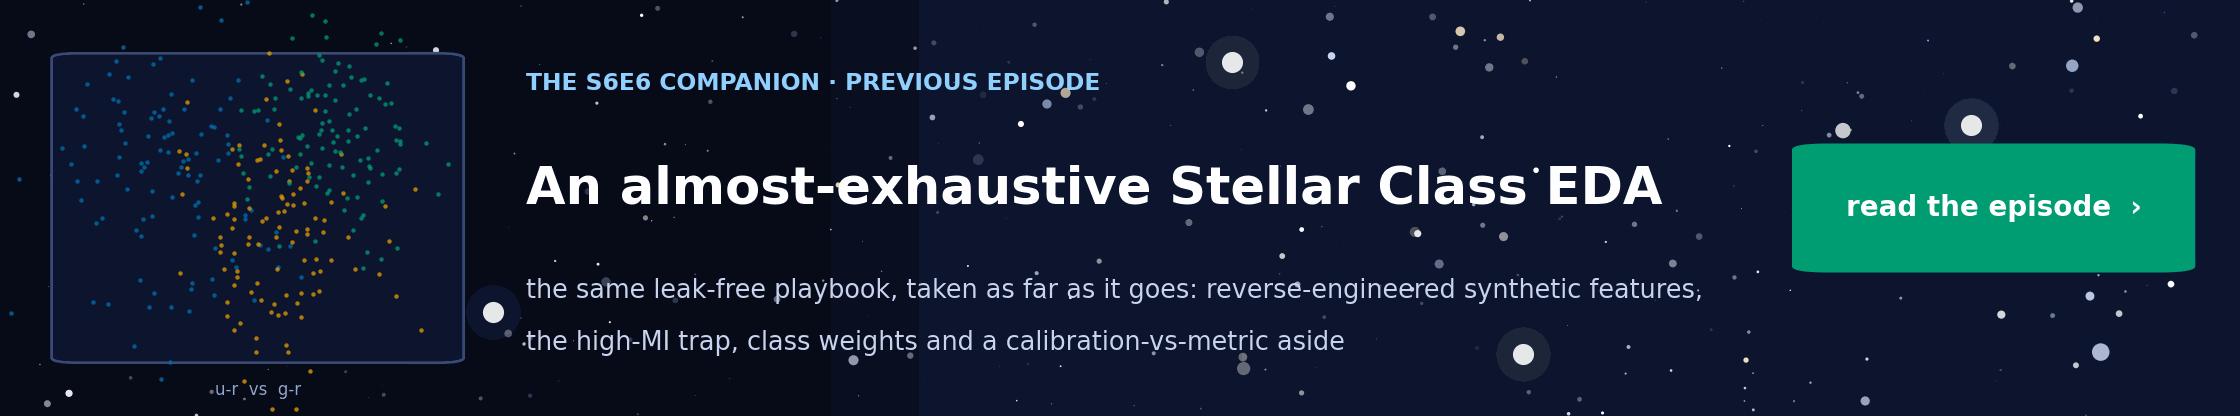</a>
<a href="https://www.kaggle.com/code/georgymamarin/student-health-risk-why-86-accuracy-scores-0-33">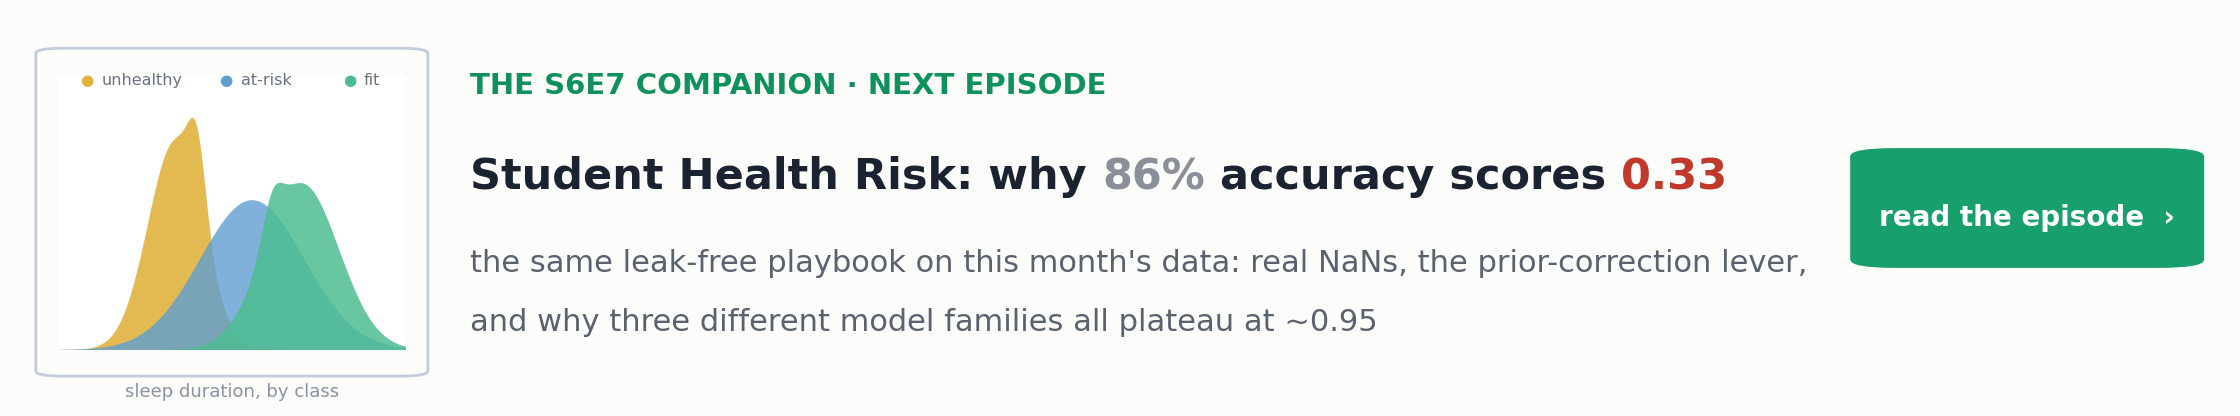</a>
</div>